
# OBAS V2 — Entrega final del proyecto

## Detección y segmentación de áreas quemadas mediante inteligencia artificial

**Equipo:** Galviz, Falla y Peña

**Aplicación:** OBAS V2 Mobile

**Tecnologías:** TensorFlow, Keras, TensorFlow Lite, Flutter y Android.

**Objetivo:** Consolidar las evidencias del entrenamiento, la optimización, la destilación, la evaluación y el despliegue móvil del modelo OBAS V2.

### Alcance del cuaderno

Este cuaderno documenta el modelo final Student MobileNetV2–UNet y permite reproducir las evaluaciones disponibles a partir de los modelos y conjuntos de datos conservados.

El entrenamiento original, las comparaciones de ensambles y la auditoría avanzada se encuentran documentados en los cuadernos históricos del proyecto. No se repite el entrenamiento ni se presentan sus resultados históricos como nuevas ejecuciones.

La evaluación distingue entre pruebas sobre parches satelitales y pruebas funcionales de la aplicación Android.


In [1]:

# PASO 1 — Verificación del entorno

import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib

print("=== ENTORNO DE EJECUCIÓN ===")
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Sistema:", platform.system())
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

print("\n=== DIRECTORIOS DE KAGGLE ===")
print("Entrada:", Path("/kaggle/input").exists())
print("Trabajo:", Path("/kaggle/working").exists())


=== ENTORNO DE EJECUCIÓN ===
Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.3.3
Matplotlib: 3.10.0
Sistema: Linux
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

=== DIRECTORIOS DE KAGGLE ===
Entrada: True
Trabajo: True



## 2. Identificación de los recursos del proyecto

Se verifica la disponibilidad de los archivos necesarios para
reproducir la evaluación del modelo final:

- Modelo Student MobileNetV2–UNet entrenado.
- Dataset OBAS V2 con imágenes y máscaras.
- Índices de partición espacial.
- Evidencias de evaluación y auditoría.
- Modelos optimizados en formato TensorFlow Lite.

Esta verificación permite identificar los recursos disponibles
antes de ejecutar nuevas inferencias, evitando repetir el
entrenamiento original.


In [2]:

# PASO 2 — Inventario de archivos disponibles en Kaggle

from pathlib import Path
import pandas as pd

RAIZ_INPUT = Path("/kaggle/input")

extensiones = {
    ".keras", ".h5", ".tflite",
    ".csv", ".json", ".zip"
}

registros = []

for archivo in RAIZ_INPUT.rglob("*"):
    if archivo.is_file() and archivo.suffix.lower() in extensiones:
        registros.append({
            "archivo": archivo.name,
            "extension": archivo.suffix.lower(),
            "tamano_mb": round(
                archivo.stat().st_size / (1024 ** 2), 2
            ),
            "ruta": str(archivo)
        })

df_inventario = pd.DataFrame(registros)

print("=== INVENTARIO DEL PROYECTO ===")
print("Archivos encontrados:", len(df_inventario))

if not df_inventario.empty:
    display(
        df_inventario.sort_values(
            ["extension", "archivo"]
        ).reset_index(drop=True)
    )

    print("\n=== MODELOS KERAS ===")
    display(
        df_inventario[
            df_inventario["extension"].isin([".keras", ".h5"])
        ]
    )

    print("\n=== MODELOS TFLITE ===")
    display(
        df_inventario[
            df_inventario["extension"] == ".tflite"
        ]
    )

    print("\n=== ARCHIVOS ZIP ===")
    display(
        df_inventario[
            df_inventario["extension"] == ".zip"
        ]
    )
else:
    print("No se encontraron archivos con las extensiones buscadas.")


=== INVENTARIO DEL PROYECTO ===
Archivos encontrados: 103


,archivo,extension,tamano_mb,ruta
0,A_Dropout_historial.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/entr...
1,B_Dropout_L2_historial.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/entr...
2,C_Dropout_L1_historial.csv,.csv,0.01,/kaggle/input/datasets/santiagofallaamaya/entr...
3,E01_Teacher_ResNet50_UNet_fase1_20261019_01045...,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
4,OBAS_V2_analisis_errores_50.csv,.csv,0.01,/kaggle/input/datasets/santiagofallaamaya/s15-...
...,...,...,...,...
98,obas_v2_student_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
99,student_baseline_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
100,student_baseline_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
101,student_baseline_float32.tflite,.tflite,30.54,/kaggle/input/datasets/santiagofallaamaya/obas...



=== MODELOS KERAS ===


,archivo,extension,tamano_mb,ruta
17,A_Dropout_mejor.keras,.keras,92.59,/kaggle/input/datasets/santiagofallaamaya/entr...
19,B_Dropout_L2_mejor.keras,.keras,92.60,/kaggle/input/datasets/santiagofallaamaya/entr...
21,C_Dropout_L1_mejor.keras,.keras,92.60,/kaggle/input/datasets/santiagofallaamaya/entr...
44,E01_Teacher_ResNet50_UNet_fase1_20261019_01045...,.keras,323.94,/kaggle/input/datasets/santiagofallaamaya/obas...
93,Student_MobileNetV2_UNet_V2_KD_best.weights.h5,.h5,31.16,/kaggle/input/datasets/santiagofallaamaya/obas...
94,Student_MobileNetV2_UNet_V2_baseline_best.keras,.keras,92.59,/kaggle/input/datasets/santiagofallaamaya/obas...
95,Teacher_ResNet50_UNet_V2_best.keras,.keras,364.49,/kaggle/input/datasets/santiagofallaamaya/obas...
99,Dropout.keras,.keras,31.35,/kaggle/input/datasets/santiagofallaamaya/obas...
100,Dropout_L1.keras,.keras,31.36,/kaggle/input/datasets/santiagofallaamaya/obas...
101,Dropout_L2.keras,.keras,31.36,/kaggle/input/datasets/santiagofallaamaya/obas...



=== MODELOS TFLITE ===


,archivo,extension,tamano_mb,ruta
14,obas_v2_student_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
32,student_baseline_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
33,student_baseline_float32.tflite,.tflite,30.54,/kaggle/input/datasets/santiagofallaamaya/obas...
83,student_baseline_float16.tflite,.tflite,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
84,student_baseline_float32.tflite,.tflite,30.54,/kaggle/input/datasets/santiagofallaamaya/obas...



=== ARCHIVOS ZIP ===


,archivo,extension,tamano_mb,ruta



## 3. Modelo Student MobileNetV2–UNet

El proyecto OBAS V2 utiliza una arquitectura de segmentación
semántica que combina MobileNetV2 como codificador y U-Net
como decodificador.

Durante el desarrollo se trabajó con modelos Teacher y
Student, así como con procesos de optimización y destilación
del conocimiento.

Para esta entrega se utiliza el archivo conservado del
modelo Student baseline, que permite reproducir las
evaluaciones de segmentación sin repetir el entrenamiento.

La aplicación Android utiliza una versión optimizada en
TensorFlow Lite Float16.

En este apartado se verifican las dimensiones de entrada,
salida y cantidad de parámetros del modelo.


In [3]:

# PASO 3 — Cargar el modelo Student

from pathlib import Path
import tensorflow as tf

ruta_modelo_student = Path(
    "/kaggle/input/datasets/santiagofallaamaya/"
    "obas-v2-final-backup/models/"
    "Student_MobileNetV2_UNet_V2_baseline_best.keras"
)

print("=== VERIFICACIÓN DEL MODELO ===")
print("Archivo:", ruta_modelo_student.name)
print("Existe:", ruta_modelo_student.exists())

if not ruta_modelo_student.exists():
    raise FileNotFoundError(
        "No se encontró el modelo Student en la ruta indicada."
    )

modelo_student = tf.keras.models.load_model(
    str(ruta_modelo_student),
    compile=False
)

print("\n=== ARQUITECTURA ===")
print("Nombre:", modelo_student.name)
print("Entrada:", modelo_student.input_shape)
print("Salida:", modelo_student.output_shape)
print("Parámetros totales:", f"{modelo_student.count_params():,}")
print(
    "Tamaño del archivo (MB):",
    round(ruta_modelo_student.stat().st_size / (1024 ** 2), 2)
)

print("\n=== RESUMEN DE CAPAS ===")
modelo_student.summary()


=== VERIFICACIÓN DEL MODELO ===
Archivo: Student_MobileNetV2_UNet_V2_baseline_best.keras
Existe: True

=== ARQUITECTURA ===
Nombre: Student_MobileNetV2_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)
Parámetros totales: 8,045,857
Tamaño del archivo (MB): 92.59

=== RESUMEN DE CAPAS ===


Model: "Student_MobileNetV2_UNet_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ student_input       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MobileNetV2_Encoder │ [(None, 64, 64,   │  2,257,984 │ student_input[0]… │
│ (Functional)        │ 96), (None, 32,   │            │                   │
│                     │ 32, 144), (None,  │            │                   │
│                     │ 16, 16, 192),     │            │                   │
│                     │ (None, 8, 8,      │            │                   │
│                     │ 576), (None, 4,   │            │                   │
│                     │ 4, 1280)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_upsample   │ (None, 8, 8,      │          0 │ MobileNetV2_Enco… │
│ (UpSampling2D)      │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_concat     │ (None, 8, 8,      │          0 │ decoder1_upsampl… │
│ (Concatenate)       │ 1856)             │            │ MobileNetV2_Enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_conv1      │ (None, 8, 8, 256) │  4,276,480 │ decoder1_concat[… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_bn1        │ (None, 8, 8, 256) │      1,024 │ decoder1_conv1[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_conv2      │ (None, 8, 8, 256) │    590,080 │ decoder1_bn1[0][… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder1_bn2        │ (None, 8, 8, 256) │      1,024 │ decoder1_conv2[0… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_upsample   │ (None, 16, 16,    │          0 │ decoder1_bn2[0][… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_concat     │ (None, 16, 16,    │          0 │ decoder2_upsampl… │
│ (Concatenate)       │ 448)              │            │ MobileNetV2_Enco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_conv1      │ (None, 16, 16,    │    516,224 │ decoder2_concat[… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_bn1        │ (None, 16, 16,    │        512 │ decoder2_conv1[0… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_conv2      │ (None, 16, 16,    │    147,584 │ decoder2_bn1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder2_bn2        │ (None, 16, 16,    │        512 │ decoder2_conv2[0… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder3_upsample   │ (None, 32, 32,    │          0 │ decoder2_bn2[0][… │
│ (UpSampling2D)      │ 128)              │            │                 

 Total params: 8,045,857 (30.69 MB)

 Trainable params: 8,009,825 (30.56 MB)

 Non-trainable params: 36,032 (140.75 KB)


## 4. Dataset y particiones de evaluación

El proyecto OBAS V2 utiliza imágenes satelitales y máscaras
de referencia para entrenar y evaluar un modelo de
segmentación binaria de áreas quemadas.

En esta sección se identifican los conjuntos de datos
disponibles, sus formatos y los archivos de partición.

Se distinguirán los conjuntos utilizados durante el
desarrollo de los conjuntos empleados en las evaluaciones
posteriores, evitando asumir independencia entre ellos
sin evidencia documental.


In [4]:

# PASO 4 — Localizar imágenes, máscaras y particiones

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

extensiones_datos = {
    ".npy", ".npz", ".csv", ".json",
    ".parquet", ".tif", ".tiff"
}

palabras_clave = (
    "mask", "mascara", "imagen", "image",
    "train", "val", "test", "split",
    "indice", "index", "patch", "tolima"
)

registros_datos = []

for archivo in raiz.rglob("*"):
    if not archivo.is_file():
        continue

    nombre = archivo.name.lower()

    if archivo.suffix.lower() not in extensiones_datos:
        continue

    if any(palabra in nombre for palabra in palabras_clave):
        registros_datos.append({
            "nombre": archivo.name,
            "extension": archivo.suffix.lower(),
            "tamano_mb": round(
                archivo.stat().st_size / (1024 ** 2), 2
            ),
            "ruta": str(archivo)
        })

df_datos = pd.DataFrame(registros_datos)

print("=== RECURSOS DE DATOS IDENTIFICADOS ===")
print("Total:", len(df_datos))

if not df_datos.empty:
    print("\n=== RESUMEN POR EXTENSIÓN ===")
    display(
        df_datos.groupby("extension")
        .size()
        .reset_index(name="cantidad")
    )

    print("\n=== ÍNDICES Y PARTICIONES ===")
    patron = r"train|val|test|split|indice|index"

    display(
        df_datos[
            df_datos["nombre"].str.contains(
                patron, case=False, regex=True
            )
        ].head(50)
    )

    print("\n=== MUESTRA DE IMÁGENES Y MÁSCARAS ===")
    display(
        df_datos[
            df_datos["extension"].isin(
                [".npy", ".npz", ".tif", ".tiff"]
            )
        ].head(30)
    )
else:
    print("No se encontraron archivos con los filtros indicados.")


=== RECURSOS DE DATOS IDENTIFICADOS ===
Total: 75

=== RESUMEN POR EXTENSIÓN ===


,extension,cantidad
0,.csv,29
1,.json,3
2,.npy,40
3,.tif,3



=== ÍNDICES Y PARTICIONES ===


,nombre,extension,tamano_mb,ruta
1,PASO21_2_validacion_modelos.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
2,PASO21_3_comparacion_test_ABC.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
3,PASO21_3_comparacion_validacion_ABC.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
5,comparacion_final_test.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/entr...
6,comparacion_validacion.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/entr...
7,metricas_linea_base_test.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/entr...
8,patch_index_spatial_v2.csv,.csv,1.26,/kaggle/input/datasets/santiagofallaamaya/obas...
9,test_diagnostico_student.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
10,test_tflite_float32.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
15,paso33_student_test_espacial_confusion.csv,.csv,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...



=== MUESTRA DE IMÁGENES Y MÁSCARAS ===


,nombre,extension,tamano_mb,ruta
11,student_post_mask.tif,.tif,0.01,/kaggle/input/datasets/santiagofallaamaya/obas...
12,student_pre_mask.tif,.tif,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
13,tolima_post_predicted_mask.tif,.tif,0.00,/kaggle/input/datasets/santiagofallaamaya/obas...
30,prueba_01_OBAS_zone1_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
31,prueba_02_OBAS_zone1_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
32,prueba_03_OBAS_zone2_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
33,prueba_04_OBAS_zone3_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
34,prueba_05_OBAS_zone1_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
35,prueba_06_OBAS_zone1_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...
36,prueba_07_OBAS_zone3_mascara_real.npy,.npy,0.02,/kaggle/input/datasets/santiagofallaamaya/obas...



## 5. Visualización de datos de entrada y máscaras reales

Para comprobar la estructura de los datos se selecciona una
imagen satelital utilizada en las pruebas funcionales y su
máscara de referencia.

Se verifican sus dimensiones, tipo de datos y valores,
y se presenta una comparación visual entre la imagen
original y la máscara binaria.

Esta visualización corresponde a datos preparados del
proyecto, no a fotografías nuevas capturadas en campo.


=== VERIFICACIÓN DE DIMENSIONES ===
Imagen original: (3, 128, 128)
Máscara original: (128, 128)
Tipo de imagen: float32
Imagen RGB corregida: (128, 128, 3)
Máscara: (128, 128)


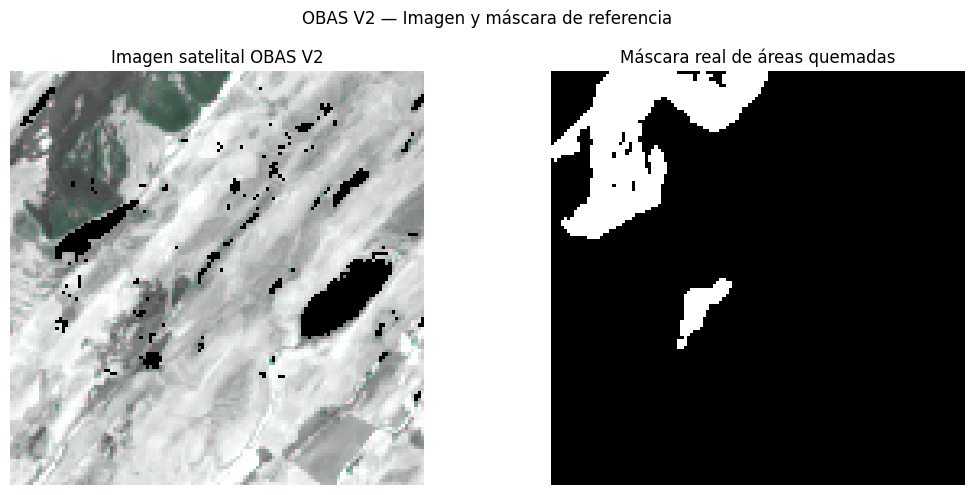

In [6]:

# PASO 5 — Corrección de la visualización satelital

import numpy as np
import matplotlib.pyplot as plt

print("=== VERIFICACIÓN DE DIMENSIONES ===")
print("Imagen original:", imagen.shape)
print("Máscara original:", mascara.shape)
print("Tipo de imagen:", imagen.dtype)

# Organizar los canales para visualización
if imagen.ndim == 3 and imagen.shape[0] == 3:
    imagen_rgb = np.transpose(imagen, (1, 2, 0))

elif imagen.ndim == 3 and imagen.shape[-1] == 3:
    imagen_rgb = imagen.copy()

else:
    raise ValueError(
        f"Formato de imagen no esperado: {imagen.shape}"
    )

# Normalización por canal para mejorar la visualización
imagen_rgb = imagen_rgb.astype(np.float32)

for canal in range(3):
    datos = imagen_rgb[:, :, canal]

    p2, p98 = np.percentile(datos, [2, 98])

    if p98 > p2:
        imagen_rgb[:, :, canal] = np.clip(
            (datos - p2) / (p98 - p2), 0, 1
        )
    else:
        imagen_rgb[:, :, canal] = 0

mascara_2d = np.squeeze(mascara)

print("Imagen RGB corregida:", imagen_rgb.shape)
print("Máscara:", mascara_2d.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(imagen_rgb)
axes[0].set_title("Imagen satelital OBAS V2")
axes[0].axis("off")

axes[1].imshow(
    mascara_2d,
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Máscara real de áreas quemadas")
axes[1].axis("off")

plt.suptitle("OBAS V2 — Imagen y máscara de referencia")
plt.tight_layout()
plt.show()



## 6. Inferencia y comparación con la máscara real

Se realiza una inferencia utilizando el modelo
Student MobileNetV2–UNet V2 baseline.

La imagen se organiza en formato (128, 128, 3),
compatible con la entrada de la red.

Se compara la predicción obtenida con la máscara
de referencia para calcular Precision, Recall,
F1-score e IoU.

Esta prueba corresponde a un parche satelital
preparado del proyecto y no constituye una
validación independiente en campo.


=== VERIFICACIÓN DE ENTRADA ===
Forma: (128, 128, 3)
Mínimo: 0.0
Máximo: 0.9642857313156128
Media: 0.45687422156333923

=== RESULTADOS DE INFERENCIA ===
Tiempo de inferencia: 181.65 ms
Precision: 0.9553
Recall: 0.9600
F1-score: 0.9576
IoU: 0.9187
TP: 1537 | FP: 72 | FN: 64 | TN: 14711


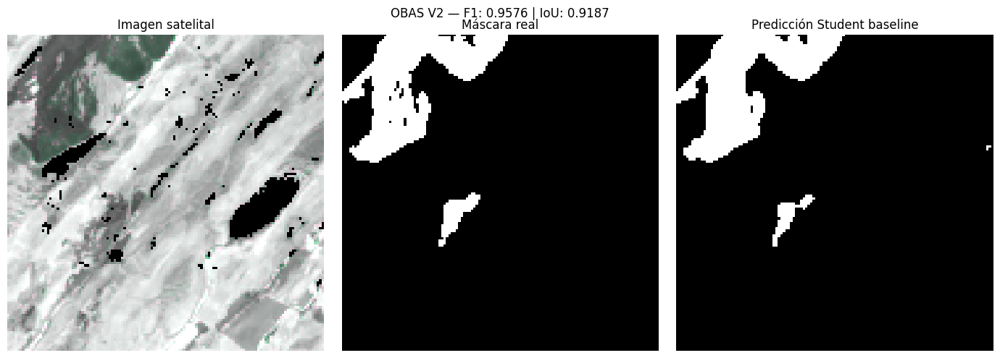

In [7]:

# PASO 6 — Inferencia del modelo Student baseline

import numpy as np
import matplotlib.pyplot as plt
import time

# Recuperar imagen original, sin normalización visual
imagen_modelo = np.asarray(imagen, dtype=np.float32)

if imagen_modelo.shape == (3, 128, 128):
    imagen_modelo = np.transpose(imagen_modelo, (1, 2, 0))

assert imagen_modelo.shape == (128, 128, 3), (
    f"Dimensiones inesperadas: {imagen_modelo.shape}"
)

print("=== VERIFICACIÓN DE ENTRADA ===")
print("Forma:", imagen_modelo.shape)
print("Mínimo:", float(imagen_modelo.min()))
print("Máximo:", float(imagen_modelo.max()))
print("Media:", float(imagen_modelo.mean()))

# Verificar si el archivo ya está normalizado
# No aplicar automáticamente la normalización visual.
if imagen_modelo.min() < 0 or imagen_modelo.max() > 1:
    print(
        "\nATENCIÓN: los valores están fuera de [0, 1]. "
        "Verifica el preprocesamiento original antes de inferir."
    )
else:
    entrada = np.expand_dims(imagen_modelo, axis=0)

    # Calentamiento del modelo
    _ = modelo_student(entrada, training=False)

    inicio = time.perf_counter()
    salida = modelo_student(entrada, training=False).numpy()
    tiempo_ms = (time.perf_counter() - inicio) * 1000

    probabilidad = np.squeeze(salida)
    prediccion = (probabilidad >= 0.5).astype(np.uint8)
    mascara_real = (np.squeeze(mascara) > 0).astype(np.uint8)

    # Métricas por píxel
    tp = np.sum((prediccion == 1) & (mascara_real == 1))
    fp = np.sum((prediccion == 1) & (mascara_real == 0))
    fn = np.sum((prediccion == 0) & (mascara_real == 1))
    tn = np.sum((prediccion == 0) & (mascara_real == 0))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0

    print("\n=== RESULTADOS DE INFERENCIA ===")
    print(f"Tiempo de inferencia: {tiempo_ms:.2f} ms")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"IoU: {iou:.4f}")
    print(f"TP: {tp} | FP: {fp} | FN: {fn} | TN: {tn}")

    # Visualización
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))

    axes[0].imshow(imagen_rgb)
    axes[0].set_title("Imagen satelital")

    axes[1].imshow(mascara_real, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Máscara real")

    axes[2].imshow(prediccion, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicción Student baseline")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(
        f"OBAS V2 — F1: {f1:.4f} | IoU: {iou:.4f}"
    )
    plt.tight_layout()
    plt.show()



## 7. Evaluación del modelo Student en 20 parches satelitales

Se evalúa el modelo Student MobileNetV2–UNet V2 baseline
sobre 20 pares de imágenes satelitales y máscaras
de referencia preparados para las pruebas funcionales
de OBAS V2 Mobile.

Para cada parche se calculan Precision, Recall, F1-score,
IoU y tiempo de inferencia en Kaggle.

Los resultados permiten describir el comportamiento
del modelo sobre este conjunto específico.

Estos 20 parches no se presentan como un conjunto
independiente de validación ni como fotografías nuevas
capturadas en campo. Tampoco se utilizan para afirmar
el rendimiento del modelo TFLite desplegado en Android.


In [9]:

# PASO 7 — CORRECCIÓN: asociar imágenes y máscaras
# aunque estén guardadas en carpetas diferentes.

from pathlib import Path
import numpy as np
import pandas as pd
import time

raiz = Path("/kaggle/input")

archivos_imagen = sorted(
    raiz.rglob("prueba_*_imagen.npy")
)

archivos_mascara = sorted(
    raiz.rglob("prueba_*_mascara_real.npy")
)

# Índice de máscaras por nombre de archivo
indice_mascaras = {}

for ruta in archivos_mascara:
    indice_mascaras.setdefault(ruta.name, []).append(ruta)

print("Imágenes encontradas:", len(archivos_imagen))
print("Máscaras encontradas:", len(archivos_mascara))

resultados = []
sin_pareja = []

for ruta_img in archivos_imagen:

    nombre_mascara = ruta_img.name.replace(
        "_imagen.npy", "_mascara_real.npy"
    )

    candidatas = indice_mascaras.get(nombre_mascara, [])

    if len(candidatas) != 1:
        sin_pareja.append({
            "imagen": ruta_img.name,
            "mascaras_encontradas": len(candidatas)
        })
        continue

    ruta_mask = candidatas[0]

    x = np.load(ruta_img, allow_pickle=False)
    y = np.load(ruta_mask, allow_pickle=False)

    if x.shape == (3, 128, 128):
        x = np.transpose(x, (1, 2, 0))

    x = x.astype(np.float32)
    y = (np.squeeze(y) > 0).astype(np.uint8)

    if x.shape != (128, 128, 3):
        print("Imagen incompatible:", ruta_img.name)
        continue

    if y.shape != (128, 128):
        print("Máscara incompatible:", ruta_mask.name)
        continue

    if x.min() < 0 or x.max() > 1:
        print("Rango incompatible:", ruta_img.name)
        continue

    entrada = np.expand_dims(x, axis=0)

    inicio = time.perf_counter()

    prob = modelo_student(
        entrada, training=False
    ).numpy()

    tiempo_ms = (time.perf_counter() - inicio) * 1000

    pred = (
        np.squeeze(prob) >= 0.5
    ).astype(np.uint8)

    tp = int(np.sum((pred == 1) & (y == 1)))
    fp = int(np.sum((pred == 1) & (y == 0)))
    fn = int(np.sum((pred == 0) & (y == 1)))
    tn = int(np.sum((pred == 0) & (y == 0)))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0

    resultados.append({
        "archivo": ruta_img.name,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "tiempo_ms": tiempo_ms,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn
    })

df_resultados_20 = pd.DataFrame(resultados)

print("\n=== VERIFICACIÓN DE PAREJAS ===")
print("Pares evaluados:", len(df_resultados_20))
print("Imágenes sin pareja única:", len(sin_pareja))

if sin_pareja:
    display(pd.DataFrame(sin_pareja))

if not df_resultados_20.empty:

    print("\n=== RESULTADOS INDIVIDUALES ===")
    display(df_resultados_20)

    print("\n=== RESUMEN ESTADÍSTICO ===")

    resumen = df_resultados_20[
        ["precision", "recall", "f1", "iou", "tiempo_ms"]
    ].agg(["mean", "std", "min", "max"])

    display(resumen.round(4))

    TP = df_resultados_20["tp"].sum()
    FP = df_resultados_20["fp"].sum()
    FN = df_resultados_20["fn"].sum()

    precision_global = TP / (TP + FP) if TP + FP else 0
    recall_global = TP / (TP + FN) if TP + FN else 0

    f1_global = (
        2 * precision_global * recall_global /
        (precision_global + recall_global)
        if precision_global + recall_global else 0
    )

    iou_global = (
        TP / (TP + FP + FN)
        if TP + FP + FN else 0
    )

    print("\n=== MÉTRICAS GLOBALES ===")
    print(f"Precision: {precision_global:.4f}")
    print(f"Recall: {recall_global:.4f}")
    print(f"F1-score: {f1_global:.4f}")
    print(f"IoU: {iou_global:.4f}")

    salida = Path(
        "/kaggle/working/OBAS_V2_evaluacion_20_parches.csv"
    )

    df_resultados_20.to_csv(salida, index=False)

    print("\nCSV generado:", salida)



Imágenes encontradas: 20
Máscaras encontradas: 20
Rango incompatible: prueba_17_CEMS_AOI01_01_imagen.npy

=== VERIFICACIÓN DE PAREJAS ===
Pares evaluados: 19
Imágenes sin pareja única: 0

=== RESULTADOS INDIVIDUALES ===


,archivo,precision,recall,f1,iou,tiempo_ms,tp,fp,fn,tn
0,prueba_01_OBAS_zone1_imagen.npy,0.955252,0.960025,0.957632,0.918709,180.844846,1537,72,64,14711
1,prueba_02_OBAS_zone1_imagen.npy,0.000000,0.000000,0.000000,0.000000,171.995807,0,0,0,16384
2,prueba_03_OBAS_zone2_imagen.npy,0.000000,0.000000,0.000000,0.000000,170.678535,0,0,0,16384
3,prueba_04_OBAS_zone3_imagen.npy,0.000000,0.000000,0.000000,0.000000,179.560006,0,0,0,16384
4,prueba_05_OBAS_zone1_imagen.npy,0.000000,0.000000,0.000000,0.000000,172.671799,0,0,3,16381
5,prueba_06_OBAS_zone1_imagen.npy,0.223022,0.953846,0.361516,0.220641,173.666804,62,216,3,16103
6,prueba_07_OBAS_zone3_imagen.npy,0.000000,0.000000,0.000000,0.000000,171.150131,0,0,5,16379
7,prueba_08_OBAS_zone3_imagen.npy,0.848485,0.933333,0.888889,0.800000,173.411854,28,5,2,16349
8,prueba_09_OBAS_zone1_imagen.npy,0.927273,0.869318,0.897361,0.813830,169.891435,153,12,23,16196
9,prueba_10_OBAS_zone1_imagen.npy,1.000000,0.532663,0.695082,0.532663,172.331113,106,0,93,16185



=== RESUMEN ESTADÍSTICO ===


,precision,recall,f1,iou,tiempo_ms
mean,0.6215,0.6387,0.6112,0.5414,175.1599
std,0.4210,0.4075,0.4005,0.3745,5.7889
min,0.0000,0.0000,0.0000,0.0000,169.1074
max,1.0000,0.9999,0.9737,0.9487,194.8010



=== MÉTRICAS GLOBALES ===
Precision: 0.8403
Recall: 0.9348
F1-score: 0.8850
IoU: 0.7938

CSV generado: /kaggle/working/OBAS_V2_evaluacion_20_parches.csv



## 8. Evidencias del entrenamiento y la destilación

El desarrollo de OBAS V2 incluyó el entrenamiento de un
modelo Teacher basado en ResNet50–UNet y de modelos
Student basados en MobileNetV2–UNet.

También se aplicó destilación del conocimiento para
transferir información del modelo Teacher al Student,
buscando una alternativa más ligera para dispositivos
móviles.

El entrenamiento se realizó en sesiones anteriores.
Los archivos originales de modelos, pesos e historiales
se conservaron como respaldo del proyecto.

Debido a una versión histórica del notebook de
entrenamiento que no conservó todas las salidas,
esta entrega recupera los resultados verificables
desde los registros CSV y los modelos guardados.

No se afirma haber repetido el entrenamiento.


In [10]:

# PASO 8 — Recuperación de historiales de entrenamiento

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

nombres = [
    "Teacher_V2_training_log.csv",
    "Student_Baseline_V2_training_log.csv",
    "Student_KD_V2_training_log.csv"
]

historiales = {}

for nombre in nombres:

    rutas = sorted(raiz.rglob(nombre))

    print("\n" + "=" * 65)
    print("ARCHIVO:", nombre)
    print("Copias encontradas:", len(rutas))

    if not rutas:
        print("No disponible")
        continue

    # Si existen varias copias, mostrar sus ubicaciones.
    for i, ruta in enumerate(rutas):
        print(f"{i + 1}. {ruta}")

    # Leer una copia y verificar las columnas.
    ruta = rutas[0]
    df = pd.read_csv(ruta)

    historiales[nombre] = df

    print("\nFilas:", len(df))
    print("Columnas:", list(df.columns))

    print("\nPrimeras filas:")
    display(df.head(5))

    print("\nÚltimas filas:")
    display(df.tail(5))



ARCHIVO: Teacher_V2_training_log.csv
Copias encontradas: 2
1. /kaggle/input/datasets/santiagofallaamaya/obas-v2-final-backup/results/Teacher_V2_training_log.csv
2. /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_RESPALDO_CONTINUIDAD/historiales_originales/Teacher_V2_training_log.csv

Filas: 50
Columnas: ['epoch', 'accuracy', 'dice_metric', 'iou_metric', 'learning_rate', 'loss', 'precision', 'recall', 'val_accuracy', 'val_dice_metric', 'val_iou_metric', 'val_loss', 'val_precision', 'val_recall']

Primeras filas:


,epoch,accuracy,dice_metric,iou_metric,learning_rate,loss,precision,recall,val_accuracy,val_dice_metric,val_iou_metric,val_loss,val_precision,val_recall
0,0,0.989010,0.217977,0.151803,0.0001,0.411923,0.227108,0.324954,0.995841,2.425851e-07,0.010309,0.812951,0.000000,0.000000
1,1,0.993186,0.434778,0.316426,0.0001,0.296297,0.459282,0.588460,0.995801,7.453713e-04,0.010406,0.532422,0.002933,0.000029
2,2,0.994222,0.518922,0.389941,0.0001,0.252073,0.526208,0.638048,0.993577,4.048800e-01,0.298644,0.308846,0.378817,0.851068
3,3,0.994764,0.556310,0.423785,0.0001,0.232294,0.563500,0.672142,0.996411,4.380215e-01,0.331002,0.291793,0.565484,0.591362
4,4,0.995430,0.585528,0.450532,0.0001,0.218204,0.632216,0.620285,0.996193,5.067806e-01,0.392162,0.254359,0.529185,0.767654



Últimas filas:


,epoch,accuracy,dice_metric,iou_metric,learning_rate,loss,precision,recall,val_accuracy,val_dice_metric,val_iou_metric,val_loss,val_precision,val_recall
45,45,0.997754,0.757398,0.633703,0.000003,0.126510,0.828704,0.801658,0.998402,0.608157,0.491310,0.201109,0.894237,0.698267
46,46,0.997880,0.766203,0.642565,0.000002,0.121797,0.830982,0.823862,0.998377,0.596914,0.477527,0.206938,0.902133,0.683963
47,47,0.997868,0.759881,0.633858,0.000002,0.125082,0.837045,0.812720,0.998337,0.598134,0.478283,0.206413,0.909424,0.666724
48,48,0.997912,0.761935,0.638455,0.000002,0.123904,0.837622,0.820723,0.998442,0.606668,0.489104,0.201971,0.897394,0.706206
49,49,0.998081,0.765468,0.645556,0.000002,0.121733,0.850181,0.836452,0.998424,0.608409,0.488856,0.201054,0.895847,0.702880



ARCHIVO: Student_Baseline_V2_training_log.csv
Copias encontradas: 2
1. /kaggle/input/datasets/santiagofallaamaya/obas-v2-final-backup/results/Student_Baseline_V2_training_log.csv
2. /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_RESPALDO_CONTINUIDAD/historiales_originales/Student_Baseline_V2_training_log.csv

Filas: 50
Columnas: ['epoch', 'accuracy', 'dice_metric', 'iou_metric', 'learning_rate', 'loss', 'precision', 'recall', 'val_accuracy', 'val_dice_metric', 'val_iou_metric', 'val_loss', 'val_precision', 'val_recall']

Primeras filas:


,epoch,accuracy,dice_metric,iou_metric,learning_rate,loss,precision,recall,val_accuracy,val_dice_metric,val_iou_metric,val_loss,val_precision,val_recall
0,0,0.981368,0.113887,0.090661,0.0001,0.481682,0.073530,0.174101,0.995841,0.000670,0.010309,0.516351,0.000000,0.000000
1,1,0.992219,0.361694,0.258346,0.0001,0.334389,0.389046,0.457611,0.995841,0.000276,0.010309,0.520459,0.000000,0.000000
2,2,0.993518,0.463794,0.340656,0.0001,0.281843,0.478715,0.568139,0.995827,0.005115,0.011957,0.518434,0.144231,0.000715
3,3,0.994134,0.508682,0.378976,0.0001,0.257801,0.520115,0.639081,0.995811,0.019791,0.019183,0.512574,0.312715,0.006070
4,4,0.994498,0.539860,0.408506,0.0001,0.242114,0.546695,0.633928,0.995848,0.047948,0.036919,0.491411,0.501387,0.298073


... (2 outputs left out)


ARCHIVO: Student_KD_V2_training_log.csv
Copias encontradas: 2
1. /kaggle/input/datasets/santiagofallaamaya/obas-v2-final-backup/results/Student_KD_V2_training_log.csv
2. /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-continuidad-aplicacion-movil/OBAS_V2_RESPALDO_CONTINUIDAD/historiales_originales/Student_KD_V2_training_log.csv

Filas: 49
Columnas: ['epoch', 'accuracy', 'hard_loss', 'learning_rate', 'loss', 'precision', 'recall', 'soft_loss', 'val_accuracy', 'val_hard_loss', 'val_loss', 'val_precision', 'val_recall', 'val_soft_loss']

Primeras filas:


,epoch,accuracy,hard_loss,learning_rate,loss,precision,recall,soft_loss,val_accuracy,val_hard_loss,val_loss,val_precision,val_recall,val_soft_loss
0,1,0.996902,0.172012,0.0001,0.169188,0.739760,0.768016,0.168482,0.997779,0.219127,0.069830,0.690140,0.845512,0.032506
1,2,0.996777,0.166578,0.0001,0.135881,0.721957,0.776935,0.128206,0.998174,0.225528,0.071410,0.775585,0.789296,0.032881
2,3,0.996840,0.168334,0.0001,0.148725,0.741114,0.749615,0.143822,0.998183,0.222991,0.069559,0.793995,0.760535,0.031201
3,4,0.996638,0.173786,0.0001,0.143728,0.720468,0.743771,0.136213,0.998075,0.216464,0.064213,0.831309,0.673776,0.026151
4,5,0.996599,0.177365,0.0001,0.159973,0.706198,0.768586,0.155625,0.997567,0.240741,0.081527,0.668987,0.821364,0.041723



Últimas filas:


,epoch,accuracy,hard_loss,learning_rate,loss,precision,recall,soft_loss,val_accuracy,val_hard_loss,val_loss,val_precision,val_recall,val_soft_loss
44,45,0.995885,0.189953,0.000006,0.086268,0.642060,0.752605,0.060347,0.998260,0.200386,0.051652,0.819341,0.746069,0.014468
45,46,0.995740,0.193440,0.000006,0.093875,0.638333,0.714288,0.068984,0.998351,0.204327,0.052632,0.873816,0.705339,0.014708
46,47,0.995843,0.184309,0.000006,0.084130,0.639728,0.746974,0.059085,0.998361,0.201409,0.051827,0.853297,0.731679,0.014431
47,48,0.995882,0.198891,0.000006,0.097670,0.640980,0.756124,0.072364,0.998333,0.198666,0.051745,0.820307,0.767149,0.015015
48,49,0.996253,0.185786,0.000003,0.080923,0.668828,0.777998,0.054708,0.998344,0.203480,0.052118,0.852684,0.727391,0.014277



## 9. Curvas históricas de entrenamiento y destilación

Se recuperan los historiales originales de entrenamiento
del modelo Teacher ResNet50–UNet, del Student baseline
y del Student entrenado mediante destilación del conocimiento.

Se presentan las curvas de pérdida de entrenamiento y
validación, así como las métricas de segmentación
registradas durante las épocas.

Para la destilación se visualizan adicionalmente
Hard Loss y Soft Loss.

Estas gráficas se reconstruyen a partir de los archivos
CSV originales; no corresponden a un nuevo entrenamiento.


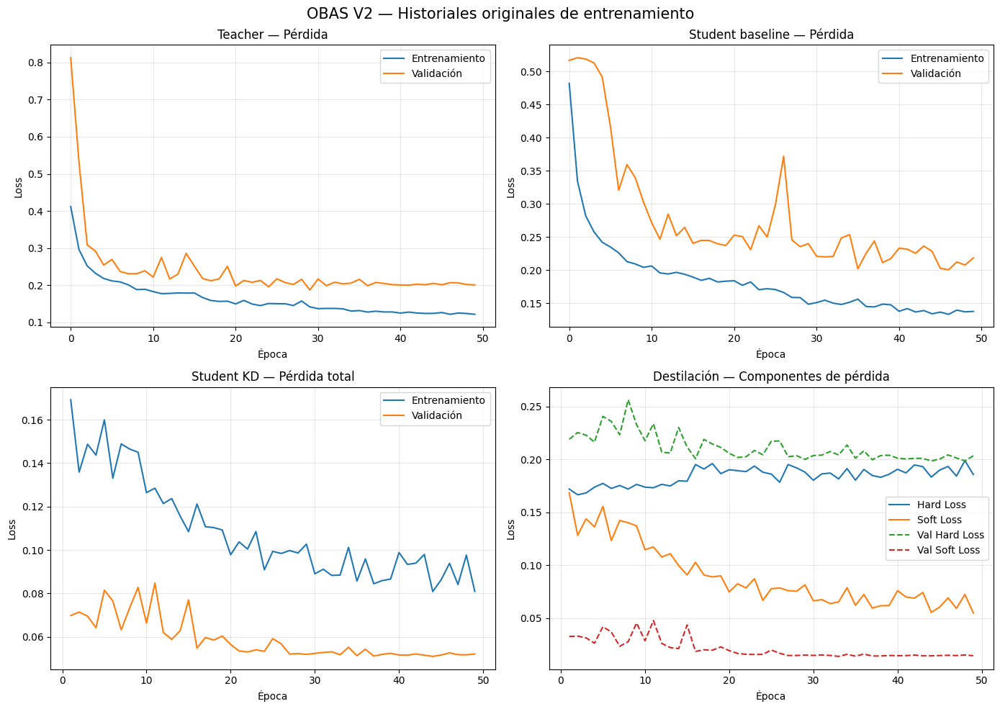

Figura guardada en: /kaggle/working/OBAS_V2_curvas_entrenamiento.png

=== ÚLTIMA ÉPOCA REGISTRADA ===

Teacher
Época: 49
Loss: 0.1217
Val Loss: 0.2011
Val Precision: 0.8958
Val Recall: 0.7029
Val Dice: 0.6084

Student baseline
Época: 49
Loss: 0.1377
Val Loss: 0.2185
Val Precision: 0.901
Val Recall: 0.6625
Val Dice: 0.5764

Student KD
Época: 49
Loss: 0.0809
Val Loss: 0.0521
Val Precision: 0.8527
Val Recall: 0.7274


In [11]:

# PASO 9 — Gráficas históricas de entrenamiento

import matplotlib.pyplot as plt
from pathlib import Path

teacher = historiales["Teacher_V2_training_log.csv"]
baseline = historiales["Student_Baseline_V2_training_log.csv"]
kd = historiales["Student_KD_V2_training_log.csv"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Teacher
axes[0, 0].plot(
    teacher["epoch"], teacher["loss"],
    label="Entrenamiento"
)
axes[0, 0].plot(
    teacher["epoch"], teacher["val_loss"],
    label="Validación"
)
axes[0, 0].set_title("Teacher — Pérdida")
axes[0, 0].set_xlabel("Época")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Student baseline
axes[0, 1].plot(
    baseline["epoch"], baseline["loss"],
    label="Entrenamiento"
)
axes[0, 1].plot(
    baseline["epoch"], baseline["val_loss"],
    label="Validación"
)
axes[0, 1].set_title("Student baseline — Pérdida")
axes[0, 1].set_xlabel("Época")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Student KD
axes[1, 0].plot(
    kd["epoch"], kd["loss"],
    label="Entrenamiento"
)
axes[1, 0].plot(
    kd["epoch"], kd["val_loss"],
    label="Validación"
)
axes[1, 0].set_title("Student KD — Pérdida total")
axes[1, 0].set_xlabel("Época")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Hard Loss y Soft Loss
axes[1, 1].plot(
    kd["epoch"], kd["hard_loss"],
    label="Hard Loss"
)
axes[1, 1].plot(
    kd["epoch"], kd["soft_loss"],
    label="Soft Loss"
)
axes[1, 1].plot(
    kd["epoch"], kd["val_hard_loss"],
    label="Val Hard Loss", linestyle="--"
)
axes[1, 1].plot(
    kd["epoch"], kd["val_soft_loss"],
    label="Val Soft Loss", linestyle="--"
)
axes[1, 1].set_title("Destilación — Componentes de pérdida")
axes[1, 1].set_xlabel("Época")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.suptitle(
    "OBAS V2 — Historiales originales de entrenamiento",
    fontsize=15
)
plt.tight_layout()

ruta_figura = Path(
    "/kaggle/working/OBAS_V2_curvas_entrenamiento.png"
)
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

print("Figura guardada en:", ruta_figura)

# Resumen final de las métricas registradas
print("\n=== ÚLTIMA ÉPOCA REGISTRADA ===")

for nombre, df in [
    ("Teacher", teacher),
    ("Student baseline", baseline),
    ("Student KD", kd)
]:
    ultima = df.iloc[-1]

    print(f"\n{nombre}")
    print("Época:", int(ultima["epoch"]))
    print("Loss:", round(float(ultima["loss"]), 4))
    print("Val Loss:", round(float(ultima["val_loss"]), 4))
    print("Val Precision:", round(float(ultima["val_precision"]), 4))
    print("Val Recall:", round(float(ultima["val_recall"]), 4))

    if "val_dice_metric" in df.columns:
        print(
            "Val Dice:",
            round(float(ultima["val_dice_metric"]), 4)
        )



## 10. Conversión y despliegue mediante TensorFlow Lite

Durante el desarrollo de OBAS V2 se generaron versiones
optimizadas del modelo Student en formato TensorFlow Lite.

El objetivo de esta conversión fue permitir la ejecución
de inferencias directamente en dispositivos Android,
sin depender de una conexión a internet.

En esta sección se verifica el archivo TFLite Float16
conservado, sus dimensiones de entrada y salida, su
tamaño y su capacidad para ejecutar una inferencia.

La conversión original se documenta en el notebook
histórico de entrenamiento. Aquí se verifica el
artefacto resultante, sin afirmar que se ha realizado
una nueva conversión.


In [12]:

# PASO 10 — Verificación del modelo TensorFlow Lite Float16

from pathlib import Path
import tensorflow as tf
import numpy as np
import time

raiz = Path("/kaggle/input")

candidatos = sorted(
    raiz.rglob("obas_v2_student_float16.tflite")
)

if not candidatos:
    raise FileNotFoundError(
        "No se encontró obas_v2_student_float16.tflite"
    )

ruta_tflite = candidatos[0]

print("=== MODELO TENSORFLOW LITE ===")
print("Archivo:", ruta_tflite.name)
print("Ruta:", ruta_tflite)
print(
    "Tamaño (MB):",
    round(ruta_tflite.stat().st_size / (1024 ** 2), 2)
)

# Cargar el intérprete TFLite
interpreter = tf.lite.Interpreter(
    model_path=str(ruta_tflite)
)

interpreter.allocate_tensors()

entrada_info = interpreter.get_input_details()
salida_info = interpreter.get_output_details()

print("\n=== ENTRADA DEL MODELO ===")

for detalle in entrada_info:
    print("Nombre:", detalle["name"])
    print("Forma:", detalle["shape"])
    print("Tipo:", detalle["dtype"])
    print("Cuantización:", detalle["quantization"])

print("\n=== SALIDA DEL MODELO ===")

for detalle in salida_info:
    print("Nombre:", detalle["name"])
    print("Forma:", detalle["shape"])
    print("Tipo:", detalle["dtype"])
    print("Cuantización:", detalle["quantization"])

# Ejecutar una inferencia con la imagen del paso 6
entrada_tflite = np.expand_dims(
    imagen_modelo, axis=0
).astype(entrada_info[0]["dtype"])

if tuple(entrada_tflite.shape) != tuple(
    entrada_info[0]["shape"]
):
    raise ValueError(
        "La imagen no coincide con la entrada del modelo."
    )

interpreter.set_tensor(
    entrada_info[0]["index"],
    entrada_tflite
)

# Calentamiento
interpreter.invoke()

inicio = time.perf_counter()
interpreter.invoke()
tiempo_tflite_ms = (
    time.perf_counter() - inicio
) * 1000

salida_tflite = interpreter.get_tensor(
    salida_info[0]["index"]
)

print("\n=== RESULTADO DE INFERENCIA ===")
print("Salida:", salida_tflite.shape)
print("Mínimo:", float(salida_tflite.min()))
print("Máximo:", float(salida_tflite.max()))
print(
    f"Tiempo de inferencia TFLite en Kaggle: "
    f"{tiempo_tflite_ms:.2f} ms"
)

print("\nVerificación TFLite completada.")


=== MODELO TENSORFLOW LITE ===
Archivo: obas_v2_student_float16.tflite
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-progreso-respaldo/obas_v2_student_float16.tflite
Tamaño (MB): 15.31

=== ENTRADA DEL MODELO ===
Nombre: serving_default_student_input:0
Forma: [  1 128 128   3]
Tipo: <class 'numpy.float32'>
Cuantización: (0.0, 0)

=== SALIDA DEL MODELO ===
Nombre: StatefulPartitionedCall_1:0
Forma: [  1 128 128   1]
Tipo: <class 'numpy.float32'>
Cuantización: (0.0, 0)

=== RESULTADO DE INFERENCIA ===
Salida: (1, 128, 128, 1)
Mínimo: 3.8473995903302616e-21
Máximo: 0.9999999403953552
Tiempo de inferencia TFLite en Kaggle: 33.29 ms

Verificación TFLite completada.


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.



## 11. Comparación funcional entre Keras y TensorFlow Lite

Se comparan las predicciones del modelo Student baseline
en formato Keras y del archivo Student TFLite Float16
conservado para el despliegue móvil.

Ambos modelos reciben el mismo parche satelital y
producen una máscara de probabilidad de áreas quemadas.

Se calculan diferencias entre sus probabilidades,
coincidencia de máscaras binarias y métricas frente
a la máscara real.

Esta comparación verifica su comportamiento funcional.
No demuestra por sí sola que ambos archivos procedan
del mismo punto de entrenamiento.


=== COMPARACIÓN DE MÉTRICAS ===


,Modelo,Precision,Recall,F1,IoU
0,Student Keras baseline,0.9553,0.96,0.9576,0.9187
1,Student TFLite Float16,0.9553,0.96,0.9576,0.9187



=== DIFERENCIAS ENTRE MODELOS ===
Diferencia media de probabilidades: 5.3e-05
Diferencia máxima de probabilidades: 0.018844
Coincidencia de máscaras binarias: 100.00%


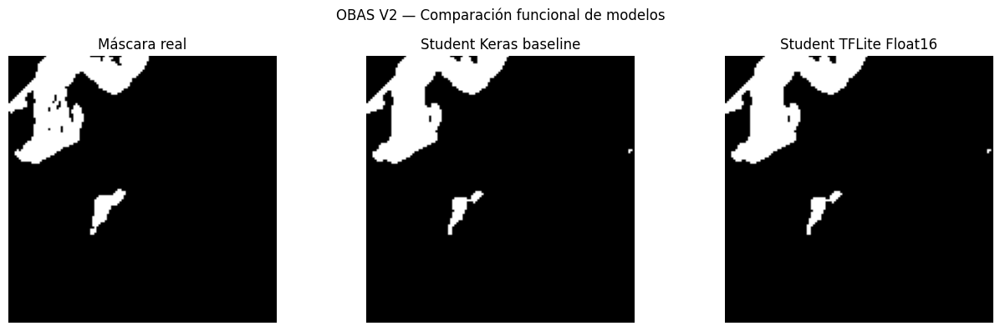

In [13]:

# PASO 11 — Comparación Keras vs TFLite

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Entrada utilizada en el paso anterior
entrada_comparacion = np.expand_dims(
    imagen_modelo, axis=0
).astype(np.float32)

# Predicción Keras
prob_keras = modelo_student(
    entrada_comparacion,
    training=False
).numpy().squeeze()

# Predicción TFLite
interpreter.set_tensor(
    entrada_info[0]["index"],
    entrada_comparacion
)
interpreter.invoke()

prob_tflite = interpreter.get_tensor(
    salida_info[0]["index"]
).squeeze()

# Máscara real
real = (np.squeeze(mascara) > 0).astype(np.uint8)

# Máscaras binarias con umbral 0.5
pred_keras = (prob_keras >= 0.5).astype(np.uint8)
pred_tflite = (prob_tflite >= 0.5).astype(np.uint8)

def metricas_binarias(real, pred):
    tp = np.sum((real == 1) & (pred == 1))
    fp = np.sum((real == 0) & (pred == 1))
    fn = np.sum((real == 1) & (pred == 0))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    iou = tp / (tp + fp + fn) if tp + fp + fn else 0

    return precision, recall, f1, iou

m_keras = metricas_binarias(real, pred_keras)
m_tflite = metricas_binarias(real, pred_tflite)

diferencia = np.abs(prob_keras - prob_tflite)
coincidencia = np.mean(pred_keras == pred_tflite)

tabla = pd.DataFrame({
    "Modelo": ["Student Keras baseline", "Student TFLite Float16"],
    "Precision": [m_keras[0], m_tflite[0]],
    "Recall": [m_keras[1], m_tflite[1]],
    "F1": [m_keras[2], m_tflite[2]],
    "IoU": [m_keras[3], m_tflite[3]]
})

print("=== COMPARACIÓN DE MÉTRICAS ===")
display(tabla.round(4))

print("\n=== DIFERENCIAS ENTRE MODELOS ===")
print(
    "Diferencia media de probabilidades:",
    round(float(diferencia.mean()), 6)
)
print(
    "Diferencia máxima de probabilidades:",
    round(float(diferencia.max()), 6)
)
print(
    "Coincidencia de máscaras binarias:",
    f"{coincidencia * 100:.2f}%"
)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(real, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Máscara real")

axes[1].imshow(pred_keras, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Student Keras baseline")

axes[2].imshow(pred_tflite, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Student TFLite Float16")

for ax in axes:
    ax.axis("off")

plt.suptitle("OBAS V2 — Comparación funcional de modelos")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/OBAS_V2_comparacion_Keras_TFLite.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()



## 12. Auditoría del modelo sobre 50 parches satelitales

Como parte de la evaluación técnica de OBAS V2 se realizó
una auditoría sobre una selección de 50 parches del índice
espacial identificado como test.

Esta auditoría incluyó métricas de segmentación, análisis
de errores, comparación de umbrales, curva
Precision–Recall y técnicas de explicabilidad.

En esta sección se recuperan los resultados originales
de la auditoría, sin ejecutar nuevamente el entrenamiento.

La selección de 50 parches corresponde a una partición
identificada como test en los archivos disponibles.
No se afirma independencia respecto al entrenamiento
original sin una verificación adicional.


In [14]:

# PASO 12 — Recuperar resultados originales de auditoría

from pathlib import Path
import pandas as pd
import json

raiz = Path("/kaggle/input")

archivos_auditoria = [
    "S15_metricas_globales_50_TEST.csv",
    "S15_comparacion_umbrales_50_TEST.csv",
    "S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv",
    "S15_resumen_auditoria_50_TEST.json"
]

for nombre in archivos_auditoria:

    rutas = sorted(raiz.rglob(nombre))

    print("\n" + "=" * 65)
    print("ARCHIVO:", nombre)

    if not rutas:
        print("No encontrado")
        continue

    ruta = rutas[0]
    print("Ruta:", ruta)

    if ruta.suffix == ".csv":
        df = pd.read_csv(ruta)

        print("Filas:", len(df))
        print("Columnas:", list(df.columns))

        display(df.head(10))

    elif ruta.suffix == ".json":
        with open(ruta, "r", encoding="utf-8") as f:
            datos = json.load(f)

        print(
            json.dumps(
                datos,
                indent=2,
                ensure_ascii=False
            )[:8000]
        )



ARCHIVO: S15_metricas_globales_50_TEST.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/s15-evidencias-auditoria-obas-v2/OBAS_V2_Auditoria_50_TEST/S15_metricas_globales_50_TEST.csv
Filas: 1
Columnas: ['modelo', 'parches', 'precision', 'recall', 'f1_dice', 'iou', 'accuracy', 'TN', 'FP', 'FN', 'TP', 'latencia_promedio_ms']


,modelo,parches,precision,recall,f1_dice,iou,accuracy,TN,FP,FN,TP,latencia_promedio_ms
0,Student_MobileNetV2_UNet_V2_baseline_best.keras,50,0.921712,0.720744,0.808933,0.679167,0.97152,746480,4195,19136,49389,253.313021



ARCHIVO: S15_comparacion_umbrales_50_TEST.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/s15-evidencias-auditoria-obas-v2/OBAS_V2_Auditoria_50_TEST/S15_comparacion_umbrales_50_TEST.csv
Filas: 7
Columnas: ['umbral', 'precision', 'recall', 'f1', 'TP', 'FP', 'FN']


,umbral,precision,recall,f1,TP,FP,FN
0,0.3,0.917642,0.732025,0.814391,50162,4502,18363
1,0.4,0.919681,0.726042,0.811469,49752,4345,18773
2,0.5,0.921712,0.720744,0.808933,49389,4195,19136
3,0.6,0.923771,0.714279,0.805629,48946,4039,19579
4,0.7,0.926367,0.705742,0.801143,48361,3844,20164
5,0.8,0.930959,0.691675,0.793674,47397,3515,21128
6,0.9,0.938272,0.651704,0.769163,44658,2938,23867



ARCHIVO: S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/s15-evidencias-auditoria-obas-v2/OBAS_V2_Auditoria_50_TEST/S15_PruebaDataset_50_TEST_Galviz_Falla_Pena.csv
Filas: 50
Columnas: ['archivo', 'zona', 'split', 'clase_real', 'prediccion', 'confianza', 'tiempo_respuesta_ms', 'porcentaje_area_quemada', 'precision', 'recall', 'f1', 'iou', 'pixeles_quemados_reales', 'pixeles_quemados_predichos', 'TP', 'TN', 'FP', 'FN']


,archivo,zona,split,clase_real,prediccion,confianza,tiempo_respuesta_ms,porcentaje_area_quemada,precision,recall,f1,iou,pixeles_quemados_reales,pixeles_quemados_predichos,TP,TN,FP,FN
0,OBAS_zone1_001883.npy,OBAS_zone1,test,1,1,0.999005,264.157170,0.793457,0.761538,0.712230,0.736059,0.582353,139,130,99,16214,31,40
1,OBAS_zone1_003023.npy,OBAS_zone1,test,1,1,0.999799,284.500826,0.061035,0.500000,0.555556,0.526316,0.357143,9,10,5,16370,5,4
2,OBAS_zone1_002429.npy,OBAS_zone1,test,1,1,0.999767,251.372726,0.006104,0.000000,0.000000,0.000000,0.000000,5,1,0,16378,1,5
3,OBAS_zone1_000105.npy,OBAS_zone1,test,1,0,1.000000,251.660332,0.000000,0.000000,0.000000,0.000000,0.000000,6,0,0,16378,0,6
4,OBAS_zone1_002944.npy,OBAS_zone1,test,1,1,0.999102,248.648868,0.311279,0.372549,0.703704,0.487179,0.322034,27,51,19,16325,32,8
5,OBAS_zone1_003534.npy,OBAS_zone1,test,1,1,0.999879,248.330948,0.134277,0.863636,0.950000,0.904762,0.826087,20,22,19,16361,3,1
6,OBAS_zone1_002261.npy,OBAS_zone1,test,1,1,0.998922,246.213550,1.898193,0.823151,0.951673,0.882759,0.790123,269,311,256,16060,55,13
7,OBAS_zone1_002326.npy,OBAS_zone1,test,1,1,0.997175,244.191688,3.796387,0.819936,0.917266,0.865874,0.763473,556,622,510,15716,112,46
8,OBAS_zone1_000764.npy,OBAS_zone1,test,0,0,0.999999,259.740681,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0
9,OBAS_zone1_002502.npy,OBAS_zone1,test,0,0,0.999999,248.786670,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0



ARCHIVO: S15_resumen_auditoria_50_TEST.json
Ruta: /kaggle/input/datasets/santiagofallaamaya/s15-evidencias-auditoria-obas-v2/OBAS_V2_Auditoria_50_TEST/S15_resumen_auditoria_50_TEST.json
{
  "proyecto": "OBAS V2",
  "auditoria": "Semana 15",
  "modelo": "Student_MobileNetV2_UNet_V2_baseline_best.keras",
  "fecha_generacion_utc": "2026-11-12T22:24:18.735539+00:00",
  "numero_parches": 50,
  "tamano_parche": [
    128,
    128
  ],
  "umbral_segmentacion": 0.5,
  "indice_seleccion": "patch_index_spatial_v2.csv",
  "particion_declarada": "test",
  "independencia_entrenamiento_verificada": false,
  "limitacion": "No se dispone de evidencia concluyente de que el modelo Student original se entrenó con la misma partición espacial. La evaluación no equivale a validación externa ni a prueba en aplicación móvil.",
  "matriz_confusion_pixeles": {
    "TN": 746480,
    "FP": 4195,
    "FN": 19136,
    "TP": 49389
  },
  "metricas_globales_pixeles": {
    "precision": 0.9217117049865632,
    "recal


## 13. Visualización de los resultados de auditoría

Se presentan los resultados de la auditoría de Semana 15
realizada sobre 50 parches satelitales.

Las figuras incluyen:

1. Métricas globales de segmentación.
2. Matriz de confusión por píxel.
3. Comparación de umbrales entre 0.3 y 0.9.

Las métricas corresponden al modelo Student baseline
con un umbral de segmentación de 0.5.

El conjunto procede de una partición identificada como
test en el índice espacial disponible. Su independencia
respecto al entrenamiento original no está verificada.


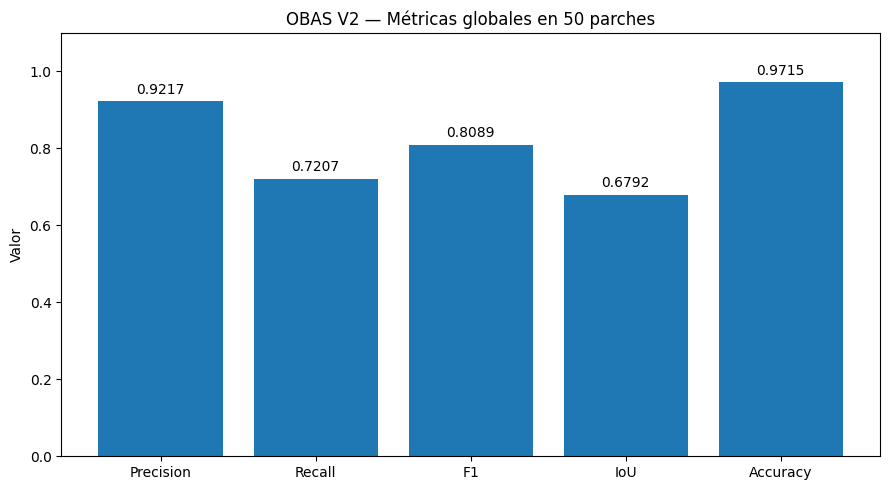

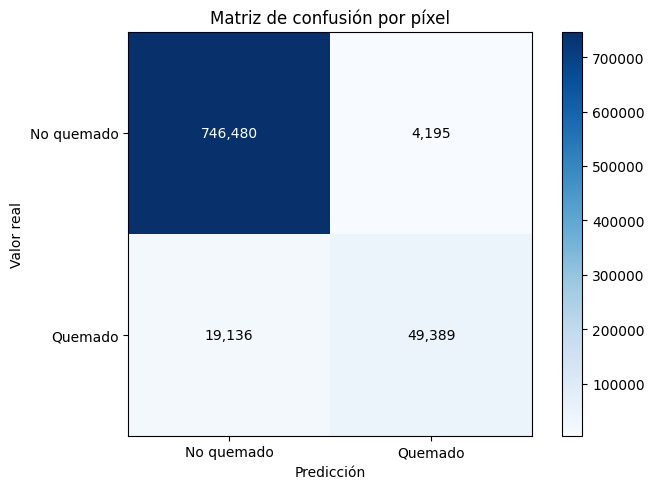

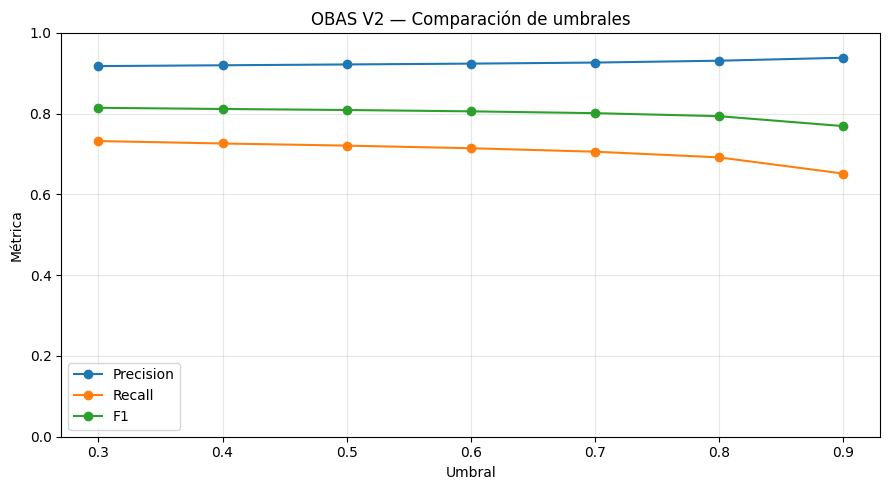

=== FIGURAS GENERADAS ===
/kaggle/working/OBAS_V2_metricas_50.png
/kaggle/working/OBAS_V2_confusion_50.png
/kaggle/working/OBAS_V2_umbrales_50.png


In [15]:

# PASO 13 — Gráficas de auditoría

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raiz = Path("/kaggle/input")

ruta_metricas = next(
    raiz.rglob("S15_metricas_globales_50_TEST.csv")
)

ruta_umbrales = next(
    raiz.rglob("S15_comparacion_umbrales_50_TEST.csv")
)

df_metricas = pd.read_csv(ruta_metricas)
df_umbrales = pd.read_csv(ruta_umbrales)

fila = df_metricas.iloc[0]

carpeta_salida = Path("/kaggle/working")
carpeta_salida.mkdir(exist_ok=True)

# FIGURA 1 — Métricas globales

nombres = ["Precision", "Recall", "F1", "IoU", "Accuracy"]
valores = [
    fila["precision"],
    fila["recall"],
    fila["f1_dice"],
    fila["iou"],
    fila["accuracy"]
]

fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(nombres, valores)

ax.set_ylim(0, 1.1)
ax.set_ylabel("Valor")
ax.set_title("OBAS V2 — Métricas globales en 50 parches")

for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.02,
        f"{valor:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    carpeta_salida / "OBAS_V2_metricas_50.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

# FIGURA 2 — Matriz de confusión por píxel

matriz = np.array([
    [int(fila["TN"]), int(fila["FP"])],
    [int(fila["FN"]), int(fila["TP"])]
])

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(matriz, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No quemado", "Quemado"])
ax.set_yticklabels(["No quemado", "Quemado"])

ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
ax.set_title("Matriz de confusión por píxel")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, f"{matriz[i, j]:,}",
            ha="center", va="center",
            color="white" if matriz[i, j] > matriz.max()/2
            else "black"
        )

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(
    carpeta_salida / "OBAS_V2_confusion_50.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

# FIGURA 3 — Comparación de umbrales

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    df_umbrales["umbral"],
    df_umbrales["precision"],
    marker="o", label="Precision"
)

ax.plot(
    df_umbrales["umbral"],
    df_umbrales["recall"],
    marker="o", label="Recall"
)

ax.plot(
    df_umbrales["umbral"],
    df_umbrales["f1"],
    marker="o", label="F1"
)

ax.set_xlabel("Umbral")
ax.set_ylabel("Métrica")
ax.set_title("OBAS V2 — Comparación de umbrales")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    carpeta_salida / "OBAS_V2_umbrales_50.png",
    dpi=180, bbox_inches="tight"
)
plt.show()

print("=== FIGURAS GENERADAS ===")
for nombre in [
    "OBAS_V2_metricas_50.png",
    "OBAS_V2_confusion_50.png",
    "OBAS_V2_umbrales_50.png"
]:
    print(carpeta_salida / nombre)



## 14. Robustez y explicabilidad del modelo

Durante la auditoría de OBAS V2 se analizaron posibles
errores del modelo y su comportamiento ante cambios
en las imágenes.

Las pruebas de robustez contemplaron alteraciones
como desenfoque, oscuridad y oclusión.

También se utilizaron visualizaciones Grad-CAM para
examinar las regiones de las imágenes que influyen
en las predicciones del modelo.

En esta sección se recuperan las evidencias disponibles
de la auditoría original. No se realizan nuevos
entrenamientos ni se atribuyen resultados a pruebas
que no estén documentadas.


In [16]:

# PASO 14 — Inventario de evidencias de robustez y Grad-CAM

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

palabras = (
    "gradcam", "grad_cam",
    "robust", "blur", "occlusion",
    "dark", "error", "errores"
)

extensiones = {
    ".png", ".jpg", ".jpeg",
    ".csv", ".json", ".npy"
}

archivos = []

for ruta in raiz.rglob("*"):
    if not ruta.is_file():
        continue

    texto = str(ruta).lower()

    if (
        ruta.suffix.lower() in extensiones
        and any(p in texto for p in palabras)
    ):
        archivos.append({
            "archivo": ruta.name,
            "tipo": ruta.suffix.lower(),
            "tamano_mb": round(
                ruta.stat().st_size / (1024 ** 2), 3
            ),
            "ruta": str(ruta)
        })

df_evidencias = pd.DataFrame(archivos)

print("=== EVIDENCIAS ENCONTRADAS ===")
print("Total:", len(df_evidencias))

if not df_evidencias.empty:

    print("\n=== RESUMEN POR TIPO ===")
    display(
        df_evidencias.groupby("tipo")
        .size()
        .reset_index(name="cantidad")
    )

    print("\n=== ARCHIVOS CSV Y JSON ===")
    display(
        df_evidencias[
            df_evidencias["tipo"].isin([".csv", ".json"])
        ]
    )

    print("\n=== IMÁGENES DE EVIDENCIA ===")
    display(
        df_evidencias[
            df_evidencias["tipo"].isin(
                [".png", ".jpg", ".jpeg"]
            )
        ].head(40)
    )

else:
    print("No se encontraron archivos con esos nombres.")


=== EVIDENCIAS ENCONTRADAS ===
Total: 44

=== RESUMEN POR TIPO ===


,tipo,cantidad
0,.csv,9
1,.png,35



=== ARCHIVOS CSV Y JSON ===


,archivo,tipo,tamano_mb,ruta
1,PASO20_4_gradcam_metricas_patch1527.csv,.csv,0.001,/kaggle/input/datasets/santiagofallaamaya/obas...
2,paso34_cambios_robustez_student.csv,.csv,0.000,/kaggle/input/datasets/santiagofallaamaya/obas...
3,paso34_robustez_student.csv,.csv,0.001,/kaggle/input/datasets/santiagofallaamaya/obas...
4,paso38_gradcam_metricas.csv,.csv,0.001,/kaggle/input/datasets/santiagofallaamaya/obas...
5,OBAS_V2_analisis_errores_50.csv,.csv,0.006,/kaggle/input/datasets/santiagofallaamaya/s15-...
6,OBAS_V2_analisis_errores_50_TEST.csv,.csv,0.008,/kaggle/input/datasets/santiagofallaamaya/s15-...
29,S15_control_calidad_gradcam.csv,.csv,0.001,/kaggle/input/datasets/santiagofallaamaya/s15-...
30,S15_indice_gradcam_20.csv,.csv,0.004,/kaggle/input/datasets/santiagofallaamaya/s15-...
43,PASO20_4_gradcam_metricas_patch1527.csv,.csv,0.001,/kaggle/input/datasets/santiagofallaamaya/obas...



=== IMÁGENES DE EVIDENCIA ===


,archivo,tipo,tamano_mb,ruta
0,PASO20_3_gradcam_patch1527.png,.png,0.208,/kaggle/input/datasets/santiagofallaamaya/obas...
7,S15_gradcam_prueba_inicial.png,.png,0.140,/kaggle/input/datasets/santiagofallaamaya/s15-...
8,S15_gradcam_validacion_localizada.png,.png,0.159,/kaggle/input/datasets/santiagofallaamaya/s15-...
9,01_exito_CEMS_AOI01_01_000029.png,.png,0.130,/kaggle/input/datasets/santiagofallaamaya/s15-...
10,02_exito_OBAS_zone2_002597.png,.png,0.125,/kaggle/input/datasets/santiagofallaamaya/s15-...
11,03_exito_OBAS_zone1_003534.png,.png,0.158,/kaggle/input/datasets/santiagofallaamaya/s15-...
12,04_exito_CEMS_AOI01_01_000071.png,.png,0.147,/kaggle/input/datasets/santiagofallaamaya/s15-...
13,05_exito_OBAS_zone2_000138.png,.png,0.143,/kaggle/input/datasets/santiagofallaamaya/s15-...
14,06_exito_OBAS_zone1_002261.png,.png,0.148,/kaggle/input/datasets/santiagofallaamaya/s15-...
15,07_exito_OBAS_zone3_003252.png,.png,0.083,/kaggle/input/datasets/santiagofallaamaya/s15-...



## 15. Análisis de robustez, errores y explicabilidad

Se recuperan los resultados históricos de las pruebas
de robustez y explicabilidad realizadas sobre OBAS V2.

El análisis incluye los registros de robustez del modelo
Student, los casos de error identificados durante la
auditoría y las evidencias visuales Grad-CAM.

Estos resultados permiten examinar las limitaciones
del modelo y documentar su comportamiento ante
distintas condiciones.

Las evidencias se recuperan de los archivos originales
del proyecto, sin repetir el entrenamiento.


In [17]:

# PASO 15 — Leer resultados de robustez y Grad-CAM

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

archivos = [
    "paso34_robustez_student.csv",
    "paso34_cambios_robustez_student.csv",
    "S15_control_calidad_gradcam.csv",
    "S15_indice_gradcam_20.csv",
    "OBAS_V2_analisis_errores_50_TEST.csv"
]

resultados_paso15 = {}

for nombre in archivos:

    rutas = sorted(raiz.rglob(nombre))

    print("\n" + "=" * 65)
    print("ARCHIVO:", nombre)

    if not rutas:
        print("No encontrado")
        continue

    ruta = rutas[0]
    df = pd.read_csv(ruta)

    resultados_paso15[nombre] = df

    print("Ruta:", ruta)
    print("Filas:", len(df))
    print("Columnas:", list(df.columns))

    display(df.head(10))

    print("\nResumen estadístico:")
    display(df.describe(include="all").T.head(20))



ARCHIVO: paso34_robustez_student.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-20261019-020316/OBAS_V2_respaldo/experimentos/paso34_robustez_student.csv
Filas: 4
Columnas: ['Condicion', 'Accuracy', 'Precision', 'Recall', 'Dice_F1', 'IoU', 'TN', 'FP', 'FN', 'TP', 'Lotes_evaluados']


,Condicion,Accuracy,Precision,Recall,Dice_F1,IoU,TN,FP,FN,TP,Lotes_evaluados
0,original,0.998854,0.801188,0.793541,0.797346,0.662989,48201155,27049,28360,109004,185
1,ruido,0.948955,0.036665,0.671551,0.069534,0.036019,45804507,2423697,45117,92247,185
2,brillo,0.998468,0.915823,0.507142,0.652795,0.484555,48221801,6403,67701,69663,185
3,desenfoque,0.996023,0.037281,0.016132,0.022520,0.011388,48170980,57224,135148,2216,185



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Condicion,4,4,original,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Accuracy,4.0,NaN,NaN,NaN,0.985575,0.024445,0.948955,0.984256,0.997245,0.998564,0.998854
Precision,4.0,NaN,NaN,NaN,0.447739,0.476615,0.036665,0.037127,0.419235,0.829847,0.915823
Recall,4.0,NaN,NaN,NaN,0.497092,0.341439,0.016132,0.384389,0.589347,0.702049,0.793541
Dice_F1,4.0,NaN,NaN,NaN,0.385549,0.396927,0.02252,0.05778,0.361164,0.688933,0.797346
IoU,4.0,NaN,NaN,NaN,0.298738,0.325985,0.011388,0.029861,0.260287,0.529163,0.662989
TN,4.0,NaN,NaN,NaN,47599610.75,1196917.775652,45804507.0,47579361.75,48186067.5,48206316.5,48221801.0
FP,4.0,NaN,NaN,NaN,628593.25,1196917.775652,6403.0,21887.5,42136.5,648842.25,2423697.0
FN,4.0,NaN,NaN,NaN,69081.5,46901.407317,28360.0,40927.75,56409.0,84562.75,135148.0
TP,4.0,NaN,NaN,NaN,68282.5,46901.407317,2216.0,52801.25,80955.0,96436.25,109004.0



ARCHIVO: paso34_cambios_robustez_student.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/obas-v2-respaldo-20261019-020316/OBAS_V2_respaldo/experimentos/paso34_cambios_robustez_student.csv
Filas: 4
Columnas: ['Condicion', 'Dice_F1_cambio', 'IoU_cambio', 'Recall_cambio', 'Precision_cambio']


,Condicion,Dice_F1_cambio,IoU_cambio,Recall_cambio,Precision_cambio
0,original,0.000000,0.000000,0.000000,0.000000
1,ruido,-0.727813,-0.626970,-0.121990,-0.764523
2,brillo,-0.144551,-0.178434,-0.286400,0.114635
3,desenfoque,-0.774826,-0.651601,-0.777409,-0.763906


... (10 outputs left out)


ARCHIVO: OBAS_V2_analisis_errores_50_TEST.csv
Ruta: /kaggle/input/datasets/santiagofallaamaya/s15-evidencias-auditoria-obas-v2/OBAS_V2_Auditoria_50_TEST/OBAS_V2_analisis_errores_50_TEST.csv
Filas: 50
Columnas: ['archivo', 'zona', 'split', 'clase_real', 'prediccion', 'confianza', 'tiempo_respuesta_ms', 'porcentaje_area_quemada', 'precision', 'recall', 'f1', 'iou', 'pixeles_quemados_reales', 'pixeles_quemados_predichos', 'TP', 'TN', 'FP', 'FN', 'tipo_resultado']


,archivo,zona,split,clase_real,prediccion,confianza,tiempo_respuesta_ms,porcentaje_area_quemada,precision,recall,f1,iou,pixeles_quemados_reales,pixeles_quemados_predichos,TP,TN,FP,FN,tipo_resultado
0,OBAS_zone1_001883.npy,OBAS_zone1,test,1,1,0.999005,264.157170,0.793457,0.761538,0.712230,0.736059,0.582353,139,130,99,16214,31,40,Quema detectada parcialmente
1,OBAS_zone1_003023.npy,OBAS_zone1,test,1,1,0.999799,284.500826,0.061035,0.500000,0.555556,0.526316,0.357143,9,10,5,16370,5,4,Quema detectada parcialmente
2,OBAS_zone1_002429.npy,OBAS_zone1,test,1,1,0.999767,251.372726,0.006104,0.000000,0.000000,0.000000,0.000000,5,1,0,16378,1,5,Prediccion sin superposicion
3,OBAS_zone1_000105.npy,OBAS_zone1,test,1,0,1.000000,251.660332,0.000000,0.000000,0.000000,0.000000,0.000000,6,0,0,16378,0,6,Quema no detectada
4,OBAS_zone1_002944.npy,OBAS_zone1,test,1,1,0.999102,248.648868,0.311279,0.372549,0.703704,0.487179,0.322034,27,51,19,16325,32,8,Quema detectada parcialmente
5,OBAS_zone1_003534.npy,OBAS_zone1,test,1,1,0.999879,248.330948,0.134277,0.863636,0.950000,0.904762,0.826087,20,22,19,16361,3,1,Quema detectada parcialmente
6,OBAS_zone1_002261.npy,OBAS_zone1,test,1,1,0.998922,246.213550,1.898193,0.823151,0.951673,0.882759,0.790123,269,311,256,16060,55,13,Quema detectada parcialmente
7,OBAS_zone1_002326.npy,OBAS_zone1,test,1,1,0.997175,244.191688,3.796387,0.819936,0.917266,0.865874,0.763473,556,622,510,15716,112,46,Quema detectada parcialmente
8,OBAS_zone1_000764.npy,OBAS_zone1,test,0,0,0.999999,259.740681,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0,Sin quema correctamente
9,OBAS_zone1_002502.npy,OBAS_zone1,test,0,0,0.999999,248.786670,0.000000,0.000000,0.000000,1.000000,1.000000,0,0,0,16384,0,0,Sin quema correctamente



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
archivo,50,50,OBAS_zone1_001883.npy,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zona,50,4,OBAS_zone1,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,50,1,test,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clase_real,50.0,NaN,NaN,NaN,0.52,0.504672,0.0,0.0,1.0,1.0,1.0
prediccion,50.0,NaN,NaN,NaN,0.44,0.501427,0.0,0.0,0.0,1.0,1.0
confianza,50.0,NaN,NaN,NaN,0.996463,0.012409,0.933535,0.999766,0.999983,0.999999,1.0
tiempo_respuesta_ms,50.0,NaN,NaN,NaN,253.313021,8.168485,244.092331,248.683318,251.516529,255.206815,288.20087
porcentaje_area_quemada,50.0,NaN,NaN,NaN,6.541016,20.664305,0.0,0.0,0.0,0.126648,96.826172
precision,50.0,NaN,NaN,NaN,0.307991,0.403436,0.0,0.0,0.0,0.797437,1.0
recall,50.0,NaN,NaN,NaN,0.294549,0.397234,0.0,0.0,0.0,0.694444,1.0



## 16. Resultados de robustez y visualizaciones Grad-CAM

### Robustez

Las pruebas históricas del modelo Student incluyeron
cuatro condiciones: imagen original, ruido, cambio
de brillo y desenfoque.

Los resultados muestran una disminución del desempeño
ante alteraciones visuales, especialmente ruido y
desenfoque.

Esto evidencia que el modelo todavía presenta
limitaciones de generalización ante cambios en
la calidad de las imágenes.

### Explicabilidad mediante Grad-CAM

La auditoría incluyó 20 visualizaciones Grad-CAM:
10 casos seleccionados como éxitos y 10 casos
seleccionados para analizar errores.

Los archivos fueron verificados como imágenes válidas
y los registros indican gradientes finitos.

Las visualizaciones permiten inspeccionar regiones
relevantes para la predicción, pero no constituyen
por sí solas una validación de exactitud del modelo.

### Alcance

Las pruebas de robustez y Grad-CAM corresponden
a evaluaciones históricas diferentes. No deben
interpretarse como resultados obtenidos en los
dispositivos móviles.


=== RESULTADOS DE ROBUSTEZ ===


,Condicion,Precision,Recall,Dice_F1,IoU
0,original,0.8012,0.7935,0.7973,0.6630
1,ruido,0.0367,0.6716,0.0695,0.0360
2,brillo,0.9158,0.5071,0.6528,0.4846
3,desenfoque,0.0373,0.0161,0.0225,0.0114


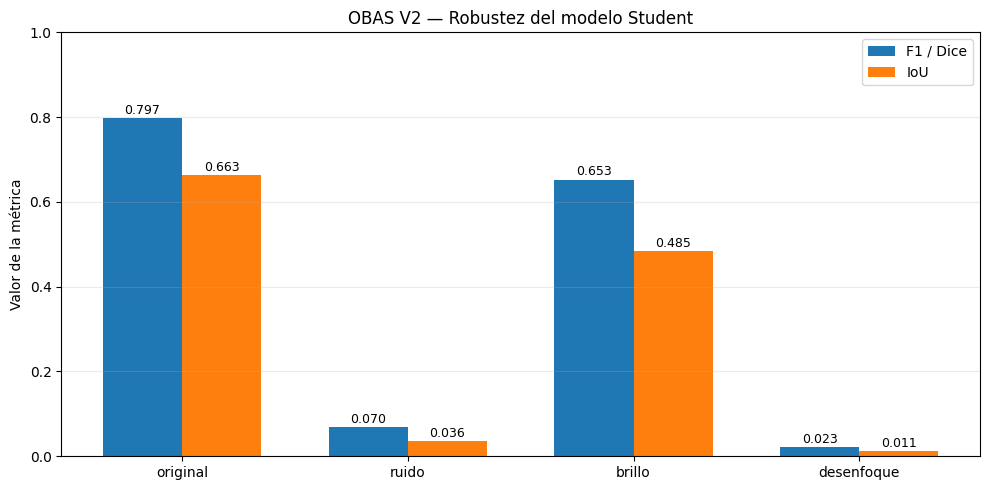

Gráfica guardada: /kaggle/working/OBAS_V2_robustez.png

=== RESUMEN GRAD-CAM ===
Total de casos: 20

Casos por grupo:


,grupo,cantidad
0,exito,10
1,error_contraste,10


Imágenes válidas: 20
Gradientes finitos: 20

Ejemplo Grad-CAM — Éxito
Archivo: 01_exito_CEMS_AOI01_01_000029.png
Dimensiones: (2044, 566)


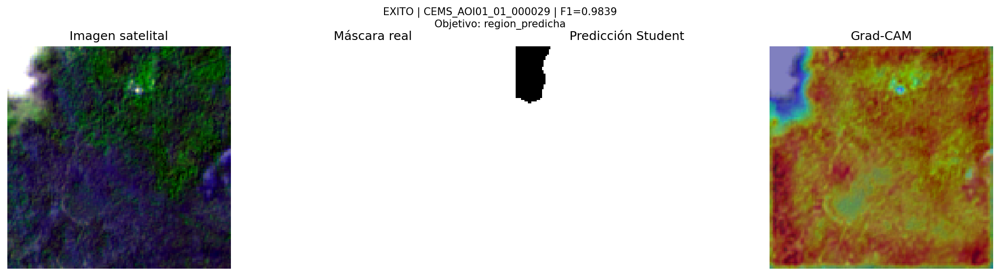


Ejemplo Grad-CAM — Análisis de error
Archivo: 11_error_contraste_OBAS_zone1_000105.png
Dimensiones: (2044, 566)


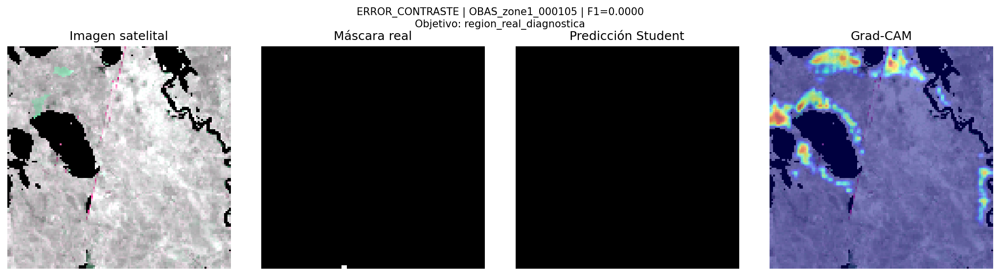


Paso 16 completado.


In [18]:

# PASO 16 — Gráfica de robustez y ejemplos Grad-CAM

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

raiz = Path("/kaggle/input")
salida = Path("/kaggle/working")

# 1. Cargar robustez original
ruta_robustez = next(
    raiz.rglob("paso34_robustez_student.csv")
)

robustez = pd.read_csv(ruta_robustez)

print("=== RESULTADOS DE ROBUSTEZ ===")
display(
    robustez[
        ["Condicion", "Precision", "Recall", "Dice_F1", "IoU"]
    ].round(4)
)

# 2. Graficar F1 e IoU por condición
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(robustez))
ancho = 0.35

b1 = ax.bar(
    x - ancho / 2,
    robustez["Dice_F1"],
    ancho,
    label="F1 / Dice"
)

b2 = ax.bar(
    x + ancho / 2,
    robustez["IoU"],
    ancho,
    label="IoU"
)

ax.set_xticks(x)
ax.set_xticklabels(robustez["Condicion"])
ax.set_ylim(0, 1)
ax.set_ylabel("Valor de la métrica")
ax.set_title("OBAS V2 — Robustez del modelo Student")
ax.legend()
ax.grid(axis="y", alpha=0.25)

for barras in [b1, b2]:
    for barra in barras:
        altura = barra.get_height()
        ax.annotate(
            f"{altura:.3f}",
            (
                barra.get_x() + barra.get_width() / 2,
                altura
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

plt.tight_layout()

ruta_grafica = salida / "OBAS_V2_robustez.png"

plt.savefig(
    ruta_grafica,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Gráfica guardada:", ruta_grafica)

# 3. Verificar el resumen de Grad-CAM
ruta_indice = next(
    raiz.rglob("S15_indice_gradcam_20.csv")
)

ruta_calidad = next(
    raiz.rglob("S15_control_calidad_gradcam.csv")
)

indice = pd.read_csv(ruta_indice)
calidad = pd.read_csv(ruta_calidad)

print("\n=== RESUMEN GRAD-CAM ===")
print("Total de casos:", len(indice))

print("\nCasos por grupo:")
display(
    indice["grupo"].value_counts()
    .rename_axis("grupo")
    .reset_index(name="cantidad")
)

print(
    "Imágenes válidas:",
    int(calidad["imagen_valida"].sum())
)

print(
    "Gradientes finitos:",
    int(indice["gradientes_finitos"].sum())
)

# 4. Mostrar dos evidencias originales
ejemplos = [
    (
        "Ejemplo Grad-CAM — Éxito",
        "01_exito_CEMS_AOI01_01_000029.png"
    ),
    (
        "Ejemplo Grad-CAM — Análisis de error",
        "11_error_contraste_OBAS_zone1_000105.png"
    )
]

for titulo, nombre in ejemplos:

    rutas = list(raiz.rglob(nombre))

    print("\n" + titulo)

    if not rutas:
        print("Imagen no encontrada:", nombre)
        continue

    imagen = Image.open(rutas[0])

    print("Archivo:", nombre)
    print("Dimensiones:", imagen.size)

    display(imagen)

print("\nPaso 16 completado.")


Imágenes encontradas: 20


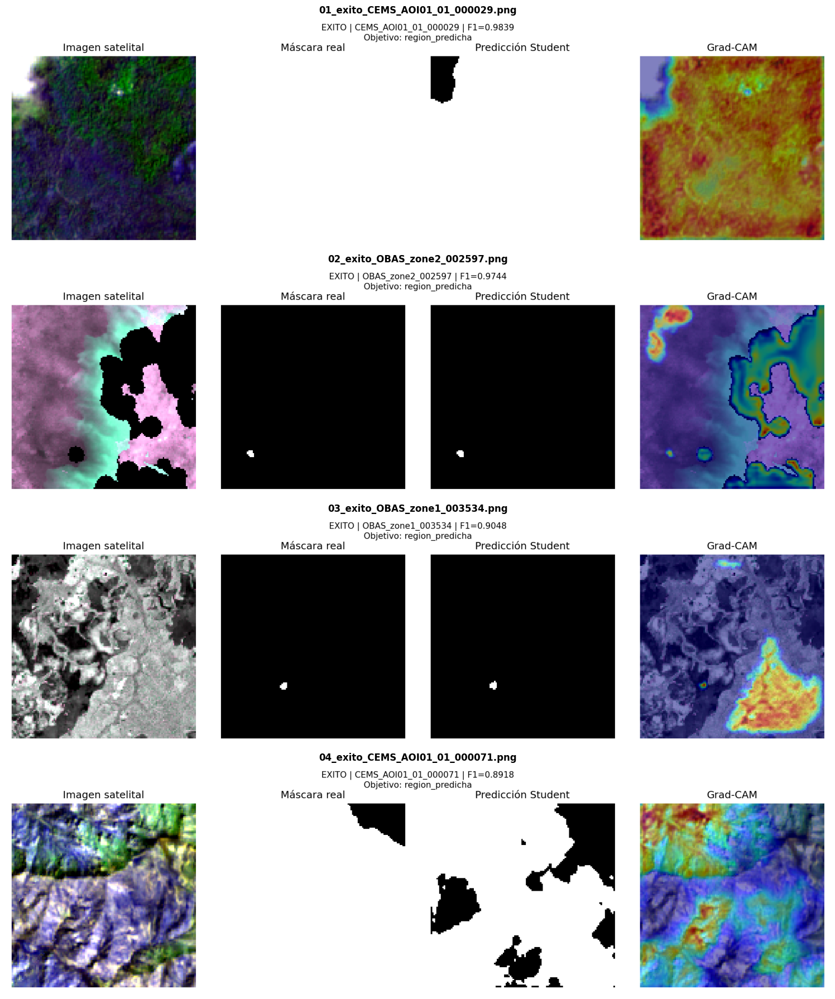

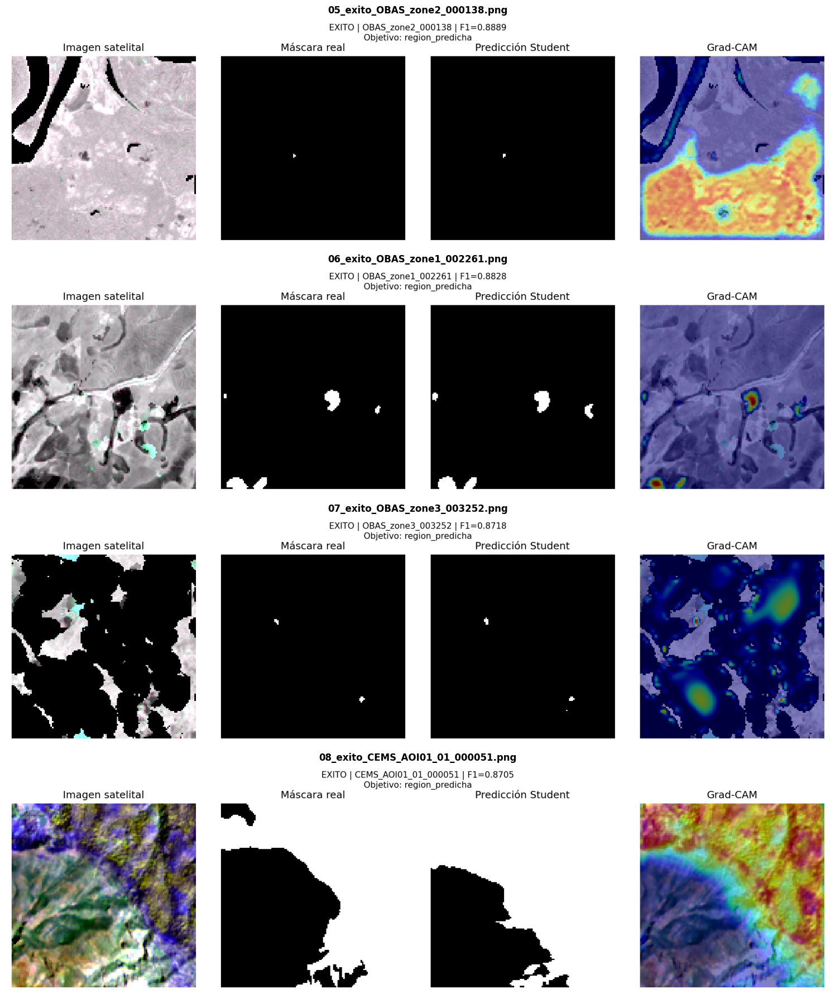

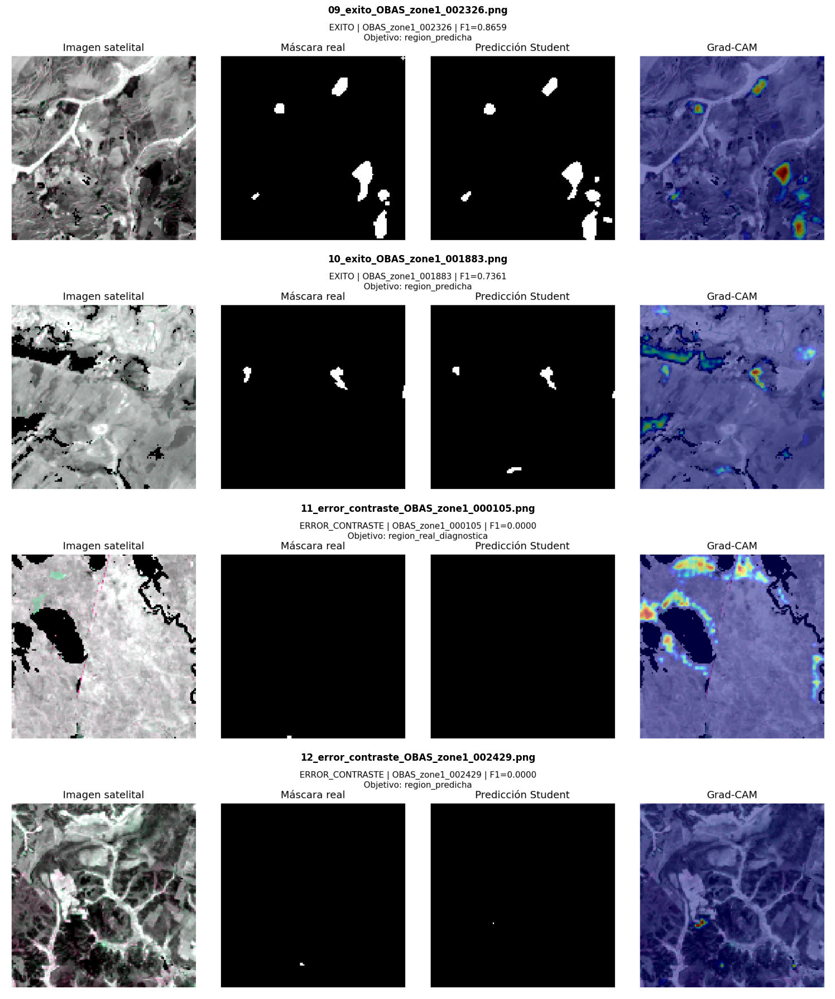

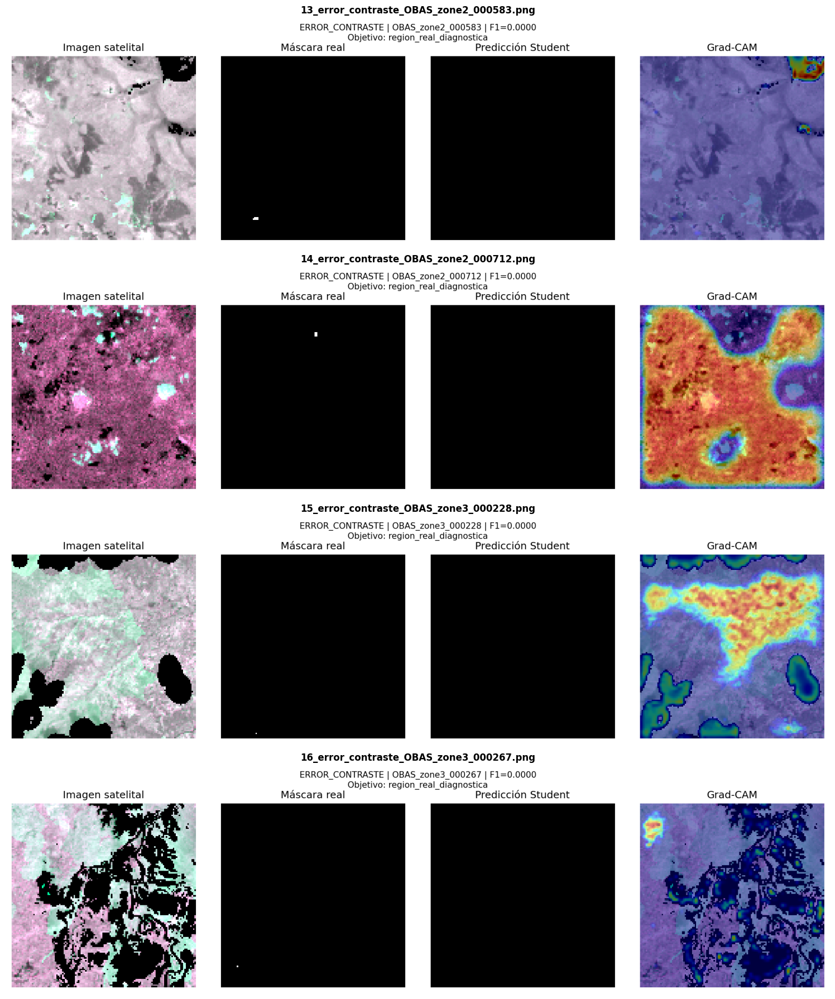

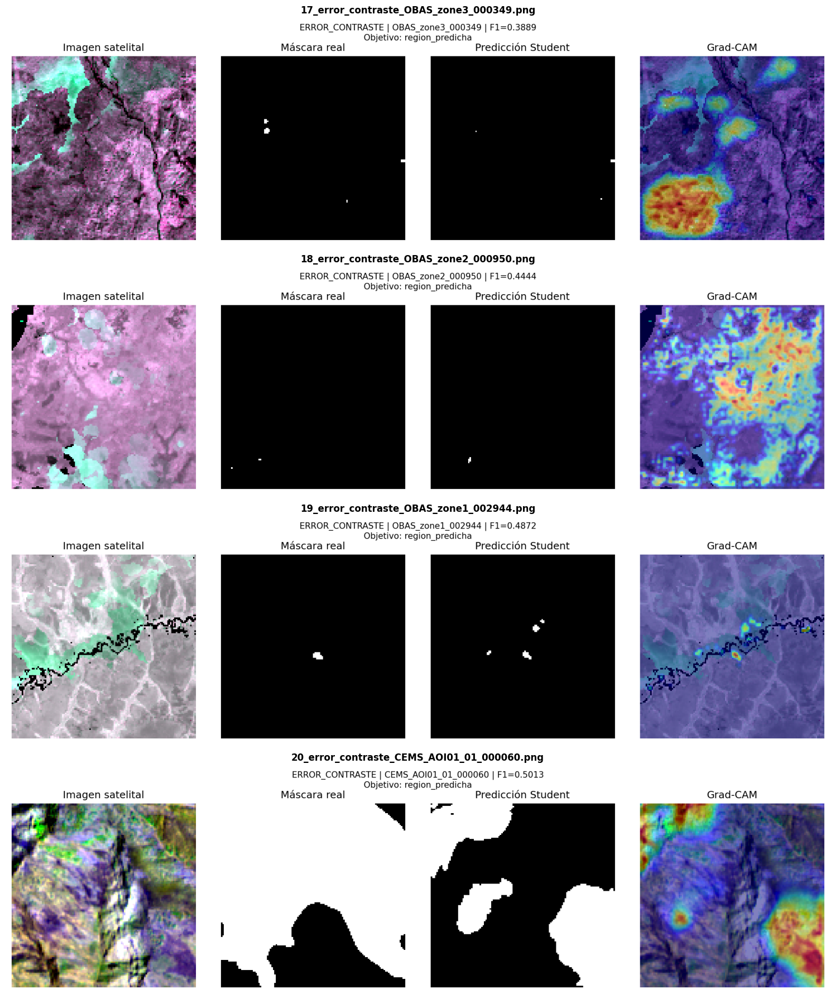

In [21]:

# PASO 16.3 — Galería para seleccionar los mejores Grad-CAM

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

raiz = Path("/kaggle/input")

# Buscar únicamente las 20 evidencias numeradas
archivos = []

for ruta in raiz.rglob("*.png"):
    nombre = ruta.name.lower()

    if (
        nombre[:2].isdigit()
        and (
            "_exito_" in nombre
            or "_error_contraste_" in nombre
        )
    ):
        archivos.append(ruta)

archivos = sorted(archivos, key=lambda p: p.name)

print("Imágenes encontradas:", len(archivos))

# Mostrar en grupos de 4 para que sean legibles
for inicio in range(0, len(archivos), 4):

    grupo = archivos[inicio:inicio + 4]

    fig, ejes = plt.subplots(
        len(grupo), 1,
        figsize=(17, 4.5 * len(grupo))
    )

    if len(grupo) == 1:
        ejes = [ejes]

    for ax, ruta in zip(ejes, grupo):
        imagen = Image.open(ruta)
        ax.imshow(imagen)
        ax.set_title(
            ruta.name,
            fontsize=12,
            fontweight="bold"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()



## 17. Trazabilidad del entrenamiento, la destilación y la conversión

El desarrollo de OBAS V2 incluyó el entrenamiento de
modelos de segmentación de áreas quemadas a partir
de imágenes satelitales.

Se trabajó con una arquitectura Teacher basada en
ResNet50–UNet y una arquitectura Student basada en
MobileNetV2–UNet.

El proyecto también incluyó experimentos de destilación
de conocimiento (Knowledge Distillation, KD), así como
la conversión de un modelo Student a TensorFlow Lite
Float16 para su integración en Android.

En esta sección se verifica la disponibilidad de los
modelos, los historiales y las evidencias de conversión.

Los resultados se recuperan de los archivos originales.
Esta sección no constituye una nueva ejecución del
entrenamiento ni de la destilación.

La aplicación móvil utiliza el modelo Student baseline
en formato TFLite Float16. No debe confundirse con el
Student entrenado mediante destilación.


In [22]:

# PASO 17 — Verificación de los artefactos del modelo

from pathlib import Path
import pandas as pd

raiz = Path("/kaggle/input")

archivos = [
    "Teacher_ResNet50_UNet_V2_best.keras",
    "Student_MobileNetV2_UNet_V2_baseline_best.keras",
    "Student_MobileNetV2_UNet_V2_KD_best.weights.h5",
    "Teacher_V2_training_log.csv",
    "Student_Baseline_V2_training_log.csv",
    "Student_KD_V2_training_log.csv",
    "obas_v2_student_float16.tflite",
    "student_baseline_float32.tflite"
]

registros = []

for nombre in archivos:

    rutas = sorted(raiz.rglob(nombre))

    if rutas:
        ruta = rutas[0]

        registros.append({
            "archivo": nombre,
            "estado": "Encontrado",
            "tamano_mb": round(
                ruta.stat().st_size / (1024 ** 2), 2
            ),
            "ruta": str(ruta)
        })

    else:
        registros.append({
            "archivo": nombre,
            "estado": "No encontrado",
            "tamano_mb": None,
            "ruta": ""
        })

df_artefactos = pd.DataFrame(registros)

print("=== ARTEFACTOS DEL PROYECTO ===")
display(df_artefactos)

# Revisar los historiales de entrenamiento

historiales = [
    "Teacher_V2_training_log.csv",
    "Student_Baseline_V2_training_log.csv",
    "Student_KD_V2_training_log.csv"
]

for nombre in historiales:

    rutas = sorted(raiz.rglob(nombre))

    if not rutas:
        continue

    df = pd.read_csv(rutas[0])

    print("\n" + "=" * 60)
    print("HISTORIAL:", nombre)
    print("Épocas registradas:", len(df))
    print("Columnas:", list(df.columns))

    print("\nPrimeras épocas:")
    display(df.head(3))

    print("\nÚltimas épocas:")
    display(df.tail(3))

print("\nVerificación de artefactos completada.")


=== ARTEFACTOS DEL PROYECTO ===


,archivo,estado,tamano_mb,ruta
0,Teacher_ResNet50_UNet_V2_best.keras,Encontrado,364.49,/kaggle/input/datasets/santiagofallaamaya/obas...
1,Student_MobileNetV2_UNet_V2_baseline_best.keras,Encontrado,92.59,/kaggle/input/datasets/santiagofallaamaya/obas...
2,Student_MobileNetV2_UNet_V2_KD_best.weights.h5,Encontrado,31.16,/kaggle/input/datasets/santiagofallaamaya/obas...
3,Teacher_V2_training_log.csv,Encontrado,0.01,/kaggle/input/datasets/santiagofallaamaya/obas...
4,Student_Baseline_V2_training_log.csv,Encontrado,0.01,/kaggle/input/datasets/santiagofallaamaya/obas...
5,Student_KD_V2_training_log.csv,Encontrado,0.01,/kaggle/input/datasets/santiagofallaamaya/obas...
6,obas_v2_student_float16.tflite,Encontrado,15.31,/kaggle/input/datasets/santiagofallaamaya/obas...
7,student_baseline_float32.tflite,Encontrado,30.54,/kaggle/input/datasets/santiagofallaamaya/obas...



HISTORIAL: Teacher_V2_training_log.csv
Épocas registradas: 50
Columnas: ['epoch', 'accuracy', 'dice_metric', 'iou_metric', 'learning_rate', 'loss', 'precision', 'recall', 'val_accuracy', 'val_dice_metric', 'val_iou_metric', 'val_loss', 'val_precision', 'val_recall']

Primeras épocas:


,epoch,accuracy,dice_metric,iou_metric,learning_rate,loss,precision,recall,val_accuracy,val_dice_metric,val_iou_metric,val_loss,val_precision,val_recall
0,0,0.989010,0.217977,0.151803,0.0001,0.411923,0.227108,0.324954,0.995841,2.425851e-07,0.010309,0.812951,0.000000,0.000000
1,1,0.993186,0.434778,0.316426,0.0001,0.296297,0.459282,0.588460,0.995801,7.453713e-04,0.010406,0.532422,0.002933,0.000029
2,2,0.994222,0.518922,0.389941,0.0001,0.252073,0.526208,0.638048,0.993577,4.048800e-01,0.298644,0.308846,0.378817,0.851068



Últimas épocas:


,epoch,accuracy,dice_metric,iou_metric,learning_rate,loss,precision,recall,val_accuracy,val_dice_metric,val_iou_metric,val_loss,val_precision,val_recall
47,47,0.997868,0.759881,0.633858,0.000002,0.125082,0.837045,0.812720,0.998337,0.598134,0.478283,0.206413,0.909424,0.666724
48,48,0.997912,0.761935,0.638455,0.000002,0.123904,0.837622,0.820723,0.998442,0.606668,0.489104,0.201971,0.897394,0.706206
49,49,0.998081,0.765468,0.645556,0.000002,0.121733,0.850181,0.836452,0.998424,0.608409,0.488856,0.201054,0.895847,0.702880


... (5 outputs left out)

,epoch,accuracy,hard_loss,learning_rate,loss,precision,recall,soft_loss,val_accuracy,val_hard_loss,val_loss,val_precision,val_recall,val_soft_loss
0,1,0.996902,0.172012,0.0001,0.169188,0.739760,0.768016,0.168482,0.997779,0.219127,0.069830,0.690140,0.845512,0.032506
1,2,0.996777,0.166578,0.0001,0.135881,0.721957,0.776935,0.128206,0.998174,0.225528,0.071410,0.775585,0.789296,0.032881
2,3,0.996840,0.168334,0.0001,0.148725,0.741114,0.749615,0.143822,0.998183,0.222991,0.069559,0.793995,0.760535,0.031201



Últimas épocas:


,epoch,accuracy,hard_loss,learning_rate,loss,precision,recall,soft_loss,val_accuracy,val_hard_loss,val_loss,val_precision,val_recall,val_soft_loss
46,47,0.995843,0.184309,0.000006,0.084130,0.639728,0.746974,0.059085,0.998361,0.201409,0.051827,0.853297,0.731679,0.014431
47,48,0.995882,0.198891,0.000006,0.097670,0.640980,0.756124,0.072364,0.998333,0.198666,0.051745,0.820307,0.767149,0.015015
48,49,0.996253,0.185786,0.000003,0.080923,0.668828,0.777998,0.054708,0.998344,0.203480,0.052118,0.852684,0.727391,0.014277



Verificación de artefactos completada.



## 18. Arquitectura y configuración del entrenamiento

### 18.1. Arquitecturas utilizadas

El proyecto OBAS V2 empleó dos arquitecturas principales
para la segmentación binaria de áreas quemadas:

- **Teacher ResNet50–UNet:** modelo de mayor capacidad,
  utilizado como referencia durante el desarrollo.
- **Student MobileNetV2–UNet:** arquitectura más ligera,
  diseñada para facilitar su implementación en dispositivos
  móviles.

Ambos modelos procesan imágenes satelitales de 128 × 128
píxeles con tres canales y producen una máscara de
probabilidades de 128 × 128 × 1.

### 18.2. Entrenamiento y destilación

Se conservan los registros de entrenamiento de:

- Teacher: 50 épocas registradas.
- Student baseline: 50 épocas registradas.
- Student KD: 49 épocas registradas, numeradas del 1 al 49.

La destilación de conocimiento se utilizó como un
experimento para transferir información del Teacher
al Student.

El modelo Student baseline fue el seleccionado para
la conversión a TensorFlow Lite Float16 y su uso en
la aplicación Android.

### 18.3. Alcance de la reconstrucción

Esta sección presenta la arquitectura y la configuración
recuperables de los modelos guardados.

Los historiales corresponden a ejecuciones anteriores.
No se realiza un nuevo entrenamiento.

El código original de entrenamiento y destilación se
conserva en el cuaderno histórico del proyecto y debe
incluirse o referenciarse en la entrega final.


In [23]:

# PASO 18 — Inspección de arquitectura y configuración

from pathlib import Path
import tensorflow as tf
import pandas as pd

raiz = Path("/kaggle/input")

modelos = {
    "Teacher ResNet50-UNet":
        "Teacher_ResNet50_UNet_V2_best.keras",

    "Student MobileNetV2-UNet":
        "Student_MobileNetV2_UNet_V2_baseline_best.keras"
}

resultados = []

for nombre, archivo in modelos.items():

    rutas = sorted(raiz.rglob(archivo))

    if not rutas:
        print("No encontrado:", archivo)
        continue

    print("\n" + "=" * 65)
    print("MODELO:", nombre)

    try:
        modelo = tf.keras.models.load_model(
            rutas[0],
            compile=False
        )

        print("Nombre interno:", modelo.name)
        print("Entrada:", modelo.input_shape)
        print("Salida:", modelo.output_shape)
        print("Parámetros:", modelo.count_params())

        print("\nResumen de arquitectura:")
        modelo.summary()

        resultados.append({
            "modelo": nombre,
            "entrada": str(modelo.input_shape),
            "salida": str(modelo.output_shape),
            "parametros": modelo.count_params(),
            "tamano_mb": round(
                rutas[0].stat().st_size / (1024 ** 2), 2
            )
        })

    except Exception as error:
        print("No se pudo cargar:", error)

print("\n=== COMPARACIÓN DE ARQUITECTURAS ===")

df_modelos = pd.DataFrame(resultados)
display(df_modelos)



MODELO: Teacher ResNet50-UNet
Nombre interno: Teacher_ResNet50_UNet_V2
Entrada: (None, 128, 128, 3)
Salida: (None, 128, 128, 1)
Parámetros: 31813505

Resumen de arquitectura:


Model: "Teacher_ResNet50_UNet_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ input_image[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_3_c

 Total params: 31,813,505 (121.36 MB)

 Trainable params: 31,760,385 (121.16 MB)

 Non-trainable params: 53,120 (207.50 KB)

... (4 outputs left out)

 Trainable params: 8,009,825 (30.56 MB)

 Non-trainable params: 36,032 (140.75 KB)


=== COMPARACIÓN DE ARQUITECTURAS ===


,modelo,entrada,salida,parametros,tamano_mb
0,Teacher ResNet50-UNet,"(None, 128, 128, 3)","(None, 128, 128, 1)",31813505,364.49
1,Student MobileNetV2-UNet,"(None, 128, 128, 3)","(None, 128, 128, 1)",8045857,92.59


In [24]:

# PASO 19 — Verificación de modelos TensorFlow Lite

from pathlib import Path
import tensorflow as tf
import pandas as pd

archivos = [
    "obas_v2_student_float16.tflite",
    "student_baseline_float32.tflite"
]

resultados = []

for archivo in archivos:
    rutas = list(Path("/kaggle/input").rglob(archivo))

    if not rutas:
        print("NO ENCONTRADO:", archivo)
        continue

    ruta = rutas[0]

    print("\n" + "=" * 60)
    print("ARCHIVO:", archivo)

    interpreter = tf.lite.Interpreter(model_path=str(ruta))
    interpreter.allocate_tensors()

    entrada = interpreter.get_input_details()[0]
    salida = interpreter.get_output_details()[0]

    print("Entrada:", entrada["shape"])
    print("Tipo de entrada:", entrada["dtype"])
    print("Salida:", salida["shape"])
    print("Tipo de salida:", salida["dtype"])

    resultados.append({
        "archivo": archivo,
        "tamano_mb": round(ruta.stat().st_size / 1024**2, 2),
        "entrada": str(entrada["shape"]),
        "salida": str(salida["shape"]),
        "dtype_entrada": str(entrada["dtype"]),
        "dtype_salida": str(salida["dtype"])
    })

print("\n=== RESUMEN TENSORFLOW LITE ===")
display(pd.DataFrame(resultados))



ARCHIVO: obas_v2_student_float16.tflite
Entrada: [  1 128 128   3]
Tipo de entrada: <class 'numpy.float32'>
Salida: [  1 128 128   1]
Tipo de salida: <class 'numpy.float32'>

ARCHIVO: student_baseline_float32.tflite


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Entrada: [  1 128 128   3]
Tipo de entrada: <class 'numpy.float32'>
Salida: [  1 128 128   1]
Tipo de salida: <class 'numpy.float32'>

=== RESUMEN TENSORFLOW LITE ===


,archivo,tamano_mb,entrada,salida,dtype_entrada,dtype_salida
0,obas_v2_student_float16.tflite,15.31,[ 1 128 128 3],[ 1 128 128 1],<class 'numpy.float32'>,<class 'numpy.float32'>
1,student_baseline_float32.tflite,30.54,[ 1 128 128 3],[ 1 128 128 1],<class 'numpy.float32'>,<class 'numpy.float32'>



## 20. Destilación de conocimiento (Knowledge Distillation)

La destilación de conocimiento es una técnica en la que un
modelo de mayor capacidad (Teacher) proporciona información
para entrenar un modelo más ligero (Student).

En OBAS V2 se trabajó con:

- Teacher: ResNet50–UNet.
- Student baseline: MobileNetV2–UNet.
- Student KD: MobileNetV2–UNet con destilación de conocimiento.

El objetivo fue estudiar si la transferencia de conocimiento
permitía mejorar el comportamiento del Student sin aumentar
significativamente la complejidad de su arquitectura.

Esta sección recupera y compara los registros históricos
de entrenamiento y validación. No ejecuta una nueva
destilación.

El procedimiento original de destilación se encuentra
documentado en el cuaderno histórico de entrenamiento
del proyecto.


In [25]:

# PASO 20 — Comparación de entrenamiento y destilación

from pathlib import Path
import pandas as pd

archivos = {
    "Teacher": "Teacher_V2_training_log.csv",
    "Student baseline": "Student_Baseline_V2_training_log.csv",
    "Student KD": "Student_KD_V2_training_log.csv"
}

resultados = []

for nombre, archivo in archivos.items():

    rutas = sorted(Path("/kaggle/input").rglob(archivo))

    if not rutas:
        print("No encontrado:", archivo)
        continue

    df = pd.read_csv(rutas[0])
    ultima = df.iloc[-1]

    resultados.append({
        "modelo": nombre,
        "registros": len(df),
        "ultima_epoca": int(ultima["epoch"]),
        "loss": round(float(ultima["loss"]), 4),
        "val_loss": round(float(ultima["val_loss"]), 4),
        "val_precision": round(
            float(ultima["val_precision"]), 4
        ),
        "val_recall": round(
            float(ultima["val_recall"]), 4
        ),
        "val_dice": (
            round(float(ultima["val_dice_metric"]), 4)
            if "val_dice_metric" in df.columns
            else None
        )
    })

comparacion_kd = pd.DataFrame(resultados)

print("=== COMPARACIÓN DE MODELOS ===")
display(comparacion_kd)

comparacion_kd.to_csv(
    "/kaggle/working/OBAS_V2_comparacion_destilacion.csv",
    index=False
)

print("CSV de comparación generado correctamente.")


=== COMPARACIÓN DE MODELOS ===


,modelo,registros,ultima_epoca,loss,val_loss,val_precision,val_recall,val_dice
0,Teacher,50,49,0.1217,0.2011,0.8958,0.7029,0.6084
1,Student baseline,50,49,0.1377,0.2185,0.9010,0.6625,0.5764
2,Student KD,49,49,0.0809,0.0521,0.8527,0.7274,NaN


CSV de comparación generado correctamente.



## 21. Conversión y optimización a TensorFlow Lite

Para implementar OBAS V2 en dispositivos Android se
seleccionó el modelo Student MobileNetV2–UNet baseline.

El modelo original se almacenó en formato Keras y
posteriormente se generaron versiones TensorFlow Lite
para su despliegue móvil.

Los archivos disponibles son:

- student_baseline_float32.tflite
- obas_v2_student_float16.tflite

La versión Float16 ocupa 15,31 MB, frente a los
30,54 MB de la versión Float32, lo que representa
una reducción aproximada del 49,9 %.

Ambos modelos reciben tensores Float32 de dimensiones
1 × 128 × 128 × 3 y devuelven tensores Float32 de
dimensiones 1 × 128 × 128 × 1.

Esta sección verifica la representación interna del
modelo optimizado. No realiza una nueva conversión.


In [26]:

# PASO 21 — Inspección de los pesos de TensorFlow Lite

from pathlib import Path
import tensorflow as tf
import numpy as np
import pandas as pd

modelos_tflite = {
    "Float32": "student_baseline_float32.tflite",
    "Float16": "obas_v2_student_float16.tflite"
}

resultados = []

for nombre, archivo in modelos_tflite.items():

    rutas = sorted(Path("/kaggle/input").rglob(archivo))

    if not rutas:
        print("No encontrado:", archivo)
        continue

    interpreter = tf.lite.Interpreter(
        model_path=str(rutas[0])
    )
    interpreter.allocate_tensors()

    detalles = interpreter.get_tensor_details()

    tipos = {}

    for detalle in detalles:
        tipo = str(detalle["dtype"])
        tipos[tipo] = tipos.get(tipo, 0) + 1

    print("\n" + "=" * 55)
    print("MODELO:", nombre)
    print("Tensores por tipo de dato:")

    for tipo, cantidad in tipos.items():
        print(tipo, ":", cantidad)

    resultados.append({
        "modelo": nombre,
        "tamano_mb": round(
            rutas[0].stat().st_size / 1024**2, 2
        ),
        "tensores_float16": sum(
            1 for d in detalles
            if d["dtype"] == np.float16
        ),
        "tensores_float32": sum(
            1 for d in detalles
            if d["dtype"] == np.float32
        ),
        "total_tensores": len(detalles)
    })

print("\n=== REPRESENTACIÓN INTERNA TFLITE ===")
display(pd.DataFrame(resultados))


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



MODELO: Float32
Tensores por tipo de dato:
<class 'numpy.float32'> : 239
<class 'numpy.int32'> : 5

MODELO: Float16
Tensores por tipo de dato:
<class 'numpy.float32'> : 239
<class 'numpy.float16'> : 140
<class 'numpy.int32'> : 5

=== REPRESENTACIÓN INTERNA TFLITE ===


,modelo,tamano_mb,tensores_float16,tensores_float32,total_tensores
0,Float32,30.54,0,239,244
1,Float16,15.31,140,239,384



## 22. Trazabilidad del código fuente y reproducibilidad

Para garantizar la trazabilidad del proyecto OBAS V2,
se revisa la disponibilidad del código fuente utilizado
en las diferentes etapas del desarrollo:

1. Preparación de datos y entrenamiento del Teacher.
2. Entrenamiento del Student baseline.
3. Destilación de conocimiento Teacher–Student.
4. Conversión y optimización a TensorFlow Lite.
5. Evaluación de los modelos.

Los modelos entrenados, los historiales y las métricas
constituyen evidencias de los experimentos realizados.

Sin embargo, para documentar completamente la metodología
también es necesario conservar el código fuente original.

Esta revisión permite identificar los archivos disponibles
y determinar cuáles deben incorporarse desde los notebooks
históricos antes de realizar la entrega definitiva.


In [27]:

# PASO 22 — Inventario del código fuente disponible

from pathlib import Path
import pandas as pd

raices = [
    Path("/kaggle/input"),
    Path("/kaggle/working")
]

extensiones = {".ipynb", ".py"}

archivos = []

for raiz in raices:
    if not raiz.exists():
        continue

    for ruta in raiz.rglob("*"):
        if ruta.is_file() and ruta.suffix.lower() in extensiones:
            archivos.append({
                "archivo": ruta.name,
                "tipo": ruta.suffix.lower(),
                "tamano_kb": round(
                    ruta.stat().st_size / 1024, 2
                ),
                "ruta": str(ruta)
            })

df_codigo = pd.DataFrame(
    archivos,
    columns=["archivo", "tipo", "tamano_kb", "ruta"]
)

print("=== INVENTARIO DE CÓDIGO FUENTE ===")
print("Archivos encontrados:", len(df_codigo))

if not df_codigo.empty:
    display(
        df_codigo.sort_values("archivo").reset_index(drop=True)
    )
else:
    print(
        "No se encontraron archivos .ipynb o .py "
        "en los directorios revisados."
    )

print("\n=== NOTEBOOKS DISPONIBLES ===")

notebooks = df_codigo[
    df_codigo["tipo"] == ".ipynb"
]

if not notebooks.empty:
    display(notebooks)
else:
    print(
        "No se encontraron notebooks históricos "
        "en los datasets revisados."
    )


=== INVENTARIO DE CÓDIGO FUENTE ===
Archivos encontrados: 1


,archivo,tipo,tamano_kb,ruta
0,__notebook_source__.ipynb,.ipynb,39.7,/kaggle/working/.virtual_documents/__notebook_...



=== NOTEBOOKS DISPONIBLES ===


,archivo,tipo,tamano_kb,ruta
0,__notebook_source__.ipynb,.ipynb,39.7,/kaggle/working/.virtual_documents/__notebook_...



## 24. Trazabilidad del entrenamiento original

### Procedencia de los modelos

El desarrollo de OBAS V2 incluyó tres experimentos:

1. **Teacher ResNet50–UNet:** modelo de referencia
   de mayor capacidad.
2. **Student MobileNetV2–UNet baseline:** modelo
   ligero entrenado de forma convencional.
3. **Student con Knowledge Distillation:** experimento
   de transferencia de conocimiento desde el Teacher.

Los tres experimentos fueron desarrollados en el
notebook histórico `modelodeteccion`.

### Configuración documentada

- Tamaño de entrada: 128 × 128 × 3.
- Salida: máscara de segmentación de 128 × 128 × 1.
- Entrenamiento Teacher: 50 épocas configuradas.
- Batch size del Teacher: 16.
- Destilación: temperatura de 4,0 y alpha de 0,8.
- Entrenamiento KD: continuación desde la época 2
  hasta completar la época 50.

### Evidencia disponible

Se conservaron los modelos entrenados, los pesos
del Student KD y los archivos CSV con los historiales
de entrenamiento.

El notebook final recupera y analiza estos artefactos.
No vuelve a ejecutar el entrenamiento histórico.

### Reproducibilidad

El código original de preparación de datos,
construcción de arquitecturas, funciones de pérdida,
entrenamiento y destilación se conserva en el
notebook `modelodeteccion`.

Los registros históricos permiten verificar los
resultados obtenidos, pero no sustituyen una
reproducción completa del entrenamiento.


In [28]:

# PASO 24 — Verificación de historiales originales

from pathlib import Path
import pandas as pd

historiales = {
    "Teacher": "Teacher_V2_training_log.csv",
    "Student baseline": "Student_Baseline_V2_training_log.csv",
    "Student KD": "Student_KD_V2_training_log.csv"
}

filas = []

for nombre, archivo in historiales.items():

    rutas = list(Path("/kaggle/input").rglob(archivo))

    if not rutas:
        print("NO ENCONTRADO:", archivo)
        continue

    df = pd.read_csv(rutas[0])

    filas.append({
        "Modelo": nombre,
        "Registros": len(df),
        "Primera época": df["epoch"].iloc[0],
        "Última época": df["epoch"].iloc[-1],
        "Archivo": archivo
    })

resumen = pd.DataFrame(filas)

print("=== TRAZABILIDAD DEL ENTRENAMIENTO ===")
display(resumen)

print("\nVerificación de archivos históricos completada.")


=== TRAZABILIDAD DEL ENTRENAMIENTO ===


,Modelo,Registros,Primera época,Última época,Archivo
0,Teacher,50,0,49,Teacher_V2_training_log.csv
1,Student baseline,50,0,49,Student_Baseline_V2_training_log.csv
2,Student KD,49,1,49,Student_KD_V2_training_log.csv



Verificación de archivos históricos completada.



## 25. Código fuente original de Knowledge Distillation

Esta sección recupera el código fuente del experimento
histórico de destilación de conocimiento.

El procedimiento original incluyó:

- Carga del Teacher ResNet50–UNet y congelación de sus pesos.
- Inicialización del Student KD desde el Student baseline.
- Cálculo de la pérdida supervisada (hard loss).
- Cálculo de la pérdida de destilación (soft loss).
- Combinación de ambas pérdidas mediante alpha = 0,8.
- Temperatura de destilación T = 4,0.
- Optimización mediante Adam.
- Registro de métricas y almacenamiento del mejor checkpoint.

Se conserva el código original para trazabilidad.
No se ejecuta un nuevo entrenamiento en esta sección.


In [30]:

# PASO 25 — Extraer código histórico de destilación

from pathlib import Path
import json

# Buscar el archivo original con su nuevo nombre
candidatos = [
    p for p in Path("/kaggle/input").rglob("*.ipynb")
    if p.name.lower() == "modelodeteccion (15).ipynb"
]

if not candidatos:
    print("No se encontró modelodeteccion (15).ipynb")
    print("Verifica que agregaste el dataset al notebook.")
else:
    ruta = candidatos[0]

    print("Archivo encontrado:", ruta)

    notebook = json.loads(
        ruta.read_text(encoding="utf-8")
    )

    celdas = notebook["cells"]

    # Celdas originales de Knowledge Distillation
    indices = [52, 54, 55]

    codigo = [
        "# OBAS V2 — CÓDIGO HISTÓRICO DE DESTILACIÓN",
        "# Extraído del notebook original.",
        "# No ejecutar sin preparar las dependencias originales.",
        ""
    ]

    for indice in indices:
        celda = celdas[indice]

        if celda["cell_type"] != "code":
            raise ValueError(
                f"La celda {indice} no es una celda de código."
            )

        contenido = "".join(celda["source"])

        codigo.extend([
            "",
            "# " + "=" * 60,
            f"# CELDA ORIGINAL {indice}",
            "# " + "=" * 60,
            contenido
        ])

        print(
            f"Celda {indice} recuperada:",
            len(contenido),
            "caracteres"
        )

    destino = Path(
        "/kaggle/working/OBAS_V2_codigo_original_KD.py"
    )

    destino.write_text(
        "\n".join(codigo),
        encoding="utf-8"
    )

    print("\nArchivo generado:", destino.name)
    print(
        "Tamaño:",
        round(destino.stat().st_size / 1024, 2),
        "KB"
    )
    print("Código histórico conservado sin reentrenamiento.")


Archivo encontrado: /kaggle/input/datasets/santiagofallaamaya/modelodeteccion15/modelodeteccion (15).ipynb
Celda 52 recuperada: 8469 caracteres
Celda 54 recuperada: 5886 caracteres
Celda 55 recuperada: 2551 caracteres

Archivo generado: OBAS_V2_codigo_original_KD.py
Tamaño: 17.13 KB
Código histórico conservado sin reentrenamiento.



## 26. Código original de conversión a TensorFlow Lite

Esta sección recupera el código fuente histórico
relacionado con la conversión del modelo Student
a TensorFlow Lite.

Se conservaron dos versiones del modelo:

- Student Float32: 30,54 MB.
- Student Float16: 15,31 MB.

La optimización permitió reducir aproximadamente
un 49,9 % el tamaño del archivo TFLite.

El modelo Float16 mantiene entradas y salidas
Float32, y contiene 140 tensores Float16 en su
representación interna.

El código se extrae del notebook histórico
`modelodeteccion` para conservar la trazabilidad
del procedimiento.

No se ejecuta una nueva conversión en esta sección.


In [31]:

# PASO 26 — Recuperar código histórico de conversión TFLite

from pathlib import Path
import json

candidatos = [
    p for p in Path("/kaggle/input").rglob("*.ipynb")
    if p.name.lower() == "modelodeteccion (15).ipynb"
]

if not candidatos:
    print("No se encontró el notebook original.")
else:
    ruta = candidatos[0]

    notebook = json.loads(
        ruta.read_text(encoding="utf-8")
    )

    celdas = notebook["cells"]

    # Celdas históricas relacionadas con TFLite
    indices = [198, 209]

    codigo = [
        "# OBAS V2 — CÓDIGO HISTÓRICO DE CONVERSIÓN TFLITE",
        "# Extraído del notebook original.",
        "# No ejecuta una nueva conversión.",
        ""
    ]

    for indice in indices:
        celda = celdas[indice]
        contenido = "".join(celda["source"])

        print("\n" + "=" * 55)
        print("CELDA ORIGINAL:", indice)
        print("Tipo:", celda["cell_type"])
        print("Caracteres:", len(contenido))
        print("Vista previa:")
        print(contenido[:700])

        if celda["cell_type"] == "code":
            codigo.extend([
                "",
                "# " + "=" * 55,
                f"# CELDA ORIGINAL {indice}",
                "# " + "=" * 55,
                contenido
            ])

    destino = Path(
        "/kaggle/working/OBAS_V2_codigo_original_TFLite.py"
    )

    destino.write_text(
        "\n".join(codigo),
        encoding="utf-8"
    )

    print("\n" + "=" * 55)
    print("Archivo generado:", destino.name)
    print(
        "Tamaño:",
        round(destino.stat().st_size / 1024, 2),
        "KB"
    )
    print("Código histórico recuperado correctamente.")



CELDA ORIGINAL: 198
Tipo: code
Caracteres: 1656
Vista previa:

from pathlib import Path
import tensorflow as tf

BACKUP_DIR = Path(
    "/kaggle/input/datasets/santiagofallaamaya/obas-v2-final-backup"
)
MODEL_PATH = (
    BACKUP_DIR / "models" /
    "Student_MobileNetV2_UNet_V2_baseline_best.keras"
)

OUTPUT_DIR = Path("/kaggle/working/obas_v2_mobile")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TFLITE_PATH = OUTPUT_DIR / "student_baseline_float32.tflite"

print("=" * 75)
print("PASO 7 — CONVERSIÓN STUDENT BASELINE A TFLITE")
print("=" * 75)

print("TensorFlow:", tf.__version__)
print("Modelo encontrado:", MODEL_PATH.is_file())

# Cargar el modelo con las funciones personalizadas del proyecto.
# compile=False evita necesitar la función de pérdida pa

CELDA ORIGINAL: 209
Tipo: code
Caracteres: 1287
Vista previa:

# PASO 23 — Conversión TFLite con cuantización float16

from pathlib import Path
import tensorflow as tf
import pandas as pd

KERAS_PATH = Path(
    "/kaggle/input/datasets


## 27. Código original de entrenamiento

En esta sección se recupera el código fuente
histórico utilizado para construir y entrenar
los modelos de segmentación de OBAS V2.

Se incluyen:

- Preparación de los datos de entrenamiento.
- Construcción de la arquitectura Teacher ResNet50–UNet.
- Definición de funciones de pérdida y métricas.
- Entrenamiento del modelo Teacher.
- Construcción de la arquitectura Student MobileNetV2–UNet.
- Entrenamiento del Student baseline.

El código se extrae directamente del notebook
original `modelodeteccion`.

Esta sección conserva el procedimiento histórico
para su revisión y reproducibilidad, sin ejecutar
un nuevo entrenamiento.


In [32]:

# PASO 27 — Recuperar código histórico de entrenamiento

from pathlib import Path
import json

candidatos = [
    p for p in Path("/kaggle/input").rglob("*.ipynb")
    if p.name.lower() == "modelodeteccion (15).ipynb"
]

if not candidatos:
    print("No se encontró el notebook original.")
else:
    ruta = candidatos[0]

    notebook = json.loads(
        ruta.read_text(encoding="utf-8")
    )

    celdas = notebook["cells"]

    secciones = {
        9: "Carga de datos",
        11: "Normalización",
        14: "Preparación y aumentación",
        19: "Arquitectura Teacher",
        26: "Pérdida y métricas",
        35: "Entrenamiento Teacher",
        41: "Arquitectura Student",
        44: "Entrenamiento Student baseline"
    }

    codigo = [
        "# OBAS V2 — CÓDIGO HISTÓRICO DE ENTRENAMIENTO",
        "# Recuperado del notebook original.",
        "# No ejecutar sin preparar el entorno original.",
        ""
    ]

    for indice, descripcion in secciones.items():
        celda = celdas[indice]
        contenido = "".join(celda["source"])

        print("\n" + "=" * 55)
        print("CELDA:", indice)
        print("SECCIÓN:", descripcion)
        print("TIPO:", celda["cell_type"])
        print("CARACTERES:", len(contenido))

        if celda["cell_type"] == "code":
            codigo.extend([
                "",
                "# " + "=" * 55,
                f"# CELDA {indice} — {descripcion}",
                "# " + "=" * 55,
                contenido
            ])
        else:
            print("Aviso: celda no incluida por no ser código.")

    destino = Path(
        "/kaggle/working/OBAS_V2_codigo_original_entrenamiento.py"
    )

    destino.write_text(
        "\n".join(codigo),
        encoding="utf-8"
    )

    print("\n" + "=" * 55)
    print("ARCHIVO GENERADO:", destino.name)
    print(
        "TAMAÑO:",
        round(destino.stat().st_size / 1024, 2),
        "KB"
    )
    print("Código original recuperado sin reentrenamiento.")



CELDA: 9
SECCIÓN: Carga de datos
TIPO: code
CARACTERES: 2862

CELDA: 11
SECCIÓN: Normalización
TIPO: code
CARACTERES: 1351

CELDA: 14
SECCIÓN: Preparación y aumentación
TIPO: code
CARACTERES: 2998

CELDA: 19
SECCIÓN: Arquitectura Teacher
TIPO: code
CARACTERES: 4382

CELDA: 26
SECCIÓN: Pérdida y métricas
TIPO: code
CARACTERES: 2791

CELDA: 35
SECCIÓN: Entrenamiento Teacher
TIPO: code
CARACTERES: 2049

CELDA: 41
SECCIÓN: Arquitectura Student
TIPO: code
CARACTERES: 3919

CELDA: 44
SECCIÓN: Entrenamiento Student baseline
TIPO: code
CARACTERES: 3089

ARCHIVO GENERADO: OBAS_V2_codigo_original_entrenamiento.py
TAMAÑO: 24.32 KB
Código original recuperado sin reentrenamiento.



## 28. Verificación del código fuente histórico

Se comprueba la disponibilidad de los tres archivos
recuperados del notebook original:

1. Código de entrenamiento del Teacher y Student.
2. Código de Knowledge Distillation.
3. Código de conversión a TensorFlow Lite.

Estos archivos conservan el procedimiento original
del proyecto OBAS V2 y complementan los modelos,
historiales de entrenamiento y resultados de evaluación.

Su generación no implica que los experimentos hayan
sido ejecutados nuevamente en este notebook.


In [34]:

# PASO 28 — Verificar archivos de código histórico

from pathlib import Path
import pandas as pd
import hashlib

directorio = Path("/kaggle/working")

archivos = [
    "OBAS_V2_codigo_original_entrenamiento.py",
    "OBAS_V2_codigo_original_KD.py",
    "OBAS_V2_codigo_original_TFLite.py"
]

resultados = []

for nombre in archivos:
    ruta = directorio / nombre

    if ruta.exists():
        contenido = ruta.read_bytes()

        resultados.append({
            "Archivo": nombre,
            "Existe": True,
            "Tamaño KB": round(len(contenido) / 1024, 2),
            "SHA256": hashlib.sha256(contenido).hexdigest()[:16]
        })
    else:
        resultados.append({
            "Archivo": nombre,
            "Existe": False,
            "Tamaño KB": None,
            "SHA256": None
        })

tabla = pd.DataFrame(resultados)

print("=== VERIFICACIÓN DEL CÓDIGO HISTÓRICO ===")
display(tabla)

completos = all(
    (directorio / nombre).is_file()
    and (directorio / nombre).stat().st_size > 0
    for nombre in archivos
)

if completos:
    print("\nCORRECTO: Los tres archivos existen y contienen datos.")
else:
    print("\nATENCIÓN: Falta uno o más archivos.")


=== VERIFICACIÓN DEL CÓDIGO HISTÓRICO ===


,Archivo,Existe,Tamaño KB,SHA256
0,OBAS_V2_codigo_original_entrenamiento.py,True,24.32,dbafadc39df8a77d
1,OBAS_V2_codigo_original_KD.py,True,17.13,34e9319da1aeaec9
2,OBAS_V2_codigo_original_TFLite.py,True,3.29,5eb7c754a1dfcf0e



CORRECTO: Los tres archivos existen y contienen datos.



## 29. Integración del código fuente histórico

Se incorporan como referencia los tres archivos de código
recuperados del notebook original `modelodeteccion`:

1. Entrenamiento del Teacher y Student baseline.
2. Destilación de conocimiento (Knowledge Distillation).
3. Conversión a TensorFlow Lite Float32 y Float16.

Estos códigos corresponden a experimentos históricos
y no se ejecutan nuevamente en esta entrega.

Los resultados del entrenamiento se documentan mediante
los modelos guardados, historiales CSV y evaluaciones
presentadas en las secciones anteriores.

La integración permite revisar el código fuente
sin repetir procesos computacionalmente costosos.


In [35]:

# PASO 29 — Crear notebook complementario de código histórico

from pathlib import Path
import nbformat

base = Path("/kaggle/working")

secciones = [
    (
        "Entrenamiento Teacher y Student",
        "OBAS_V2_codigo_original_entrenamiento.py"
    ),
    (
        "Knowledge Distillation",
        "OBAS_V2_codigo_original_KD.py"
    ),
    (
        "Conversión TensorFlow Lite",
        "OBAS_V2_codigo_original_TFLite.py"
    )
]

nb = nbformat.v4.new_notebook()

nb.cells.append(
    nbformat.v4.new_markdown_cell(
        "# OBAS V2 — Código fuente histórico\n\n"
        "Este cuaderno conserva código recuperado del "
        "notebook original `modelodeteccion`.\n\n"
        "**Las celdas de código son referencias históricas. "
        "No se ejecutaron en este cuaderno.**"
    )
)

for titulo, archivo in secciones:
    ruta = base / archivo

    if not ruta.is_file():
        raise FileNotFoundError(archivo)

    contenido = ruta.read_text(encoding="utf-8")

    nb.cells.append(
        nbformat.v4.new_markdown_cell(
            f"## {titulo}\n\n"
            "Código fuente original recuperado. "
            "No ejecutar sin reconstruir el entorno "
            "y las dependencias originales."
        )
    )

    # Se conserva como texto para evitar ejecución accidental.
    nb.cells.append(
        nbformat.v4.new_markdown_cell(
            "```python\n" + contenido + "\n```"
        )
    )

destino = base / "OBAS_V2_codigo_historico.ipynb"

nbformat.write(nb, destino)

print("=== NOTEBOOK HISTÓRICO GENERADO ===")
print("Archivo:", destino.name)
print("Celdas:", len(nb.cells))
print("Tamaño KB:", round(destino.stat().st_size / 1024, 2))
print("Entrenamiento nuevo ejecutado: NO")


=== NOTEBOOK HISTÓRICO GENERADO ===
Archivo: OBAS_V2_codigo_historico.ipynb
Celdas: 7
Tamaño KB: 63.89
Entrenamiento nuevo ejecutado: NO



## 30. Auditoría de integridad del notebook final

Antes de realizar la entrega definitiva de OBAS V2,
se verifica que el notebook principal contenga
evidencias de las etapas fundamentales del proyecto:

1. Preparación y procesamiento de datos.
2. Arquitectura y entrenamiento del Teacher.
3. Arquitectura y entrenamiento del Student baseline.
4. Destilación de conocimiento (Knowledge Distillation).
5. Conversión y optimización a TensorFlow Lite.
6. Evaluación cuantitativa y comparación de resultados.
7. Pruebas de robustez y auditoría.
8. Conservación del código fuente original.

Esta revisión identifica las secciones documentadas,
las celdas ejecutadas y los posibles elementos pendientes.

La existencia de una sección no demuestra por sí sola
que el entrenamiento o la conversión se hayan ejecutado
en este notebook.


In [37]:

# PASO 30 CORREGIDO — Auditoría del notebook
# Compatible con el archivo virtual de Kaggle

from pathlib import Path
import pandas as pd

ruta = Path(
    "/kaggle/working/.virtual_documents/"
    "__notebook_source__.ipynb"
)

categorias = {
    "Preparación de datos": [
        "normalización", "preprocesamiento",
        "dataset", "aumentación"
    ],
    "Entrenamiento Teacher y Student": [
        "teacher", "student",
        "entrenamiento", "arquitectura"
    ],
    "Knowledge Distillation": [
        "distillation", "destilación",
        "distiller"
    ],
    "TensorFlow Lite": [
        "tflite", "tensorflow lite", "float16"
    ],
    "Evaluación": [
        "evaluación", "precision",
        "recall", "f1", "iou"
    ],
    "Robustez y auditoría": [
        "robustez", "auditoría",
        "ruido", "blur"
    ],
    "Código histórico": [
        "código original",
        "código histórico",
        "trazabilidad"
    ]
}

print("=== AUDITORÍA DEL NOTEBOOK FINAL ===")

if ruta.is_file():
    contenido = ruta.read_text(
        encoding="utf-8",
        errors="replace"
    ).lower()

    print("Archivo virtual encontrado: SÍ")
    print("Tamaño:", round(ruta.stat().st_size / 1024, 2), "KB")

    resultados = []

    for categoria, palabras in categorias.items():
        encontradas = [
            palabra for palabra in palabras
            if palabra in contenido
        ]

        resultados.append({
            "Sección": categoria,
            "Palabras encontradas": ", ".join(encontradas),
            "Presencia textual": "SÍ" if encontradas else "NO"
        })

    display(pd.DataFrame(resultados))

else:
    print("Archivo virtual encontrado: NO")
    print("La revisión textual no está disponible.")

print("\n=== ARCHIVOS COMPLEMENTARIOS ===")

archivos = [
    "OBAS_V2_codigo_original_entrenamiento.py",
    "OBAS_V2_codigo_original_KD.py",
    "OBAS_V2_codigo_original_TFLite.py",
    "OBAS_V2_codigo_historico.ipynb"
]

resultados_archivos = []

for nombre in archivos:
    archivo = Path("/kaggle/working") / nombre

    resultados_archivos.append({
        "Archivo": nombre,
        "Existe": archivo.is_file(),
        "Tamaño KB": (
            round(archivo.stat().st_size / 1024, 2)
            if archivo.is_file() else None
        )
    })

display(pd.DataFrame(resultados_archivos))

print("\nAuditoría preliminar completada.")
print(
    "IMPORTANTE: esta revisión solo busca texto. "
    "No verifica celdas ejecutadas ni salidas guardadas."
)


=== AUDITORÍA DEL NOTEBOOK FINAL ===
Archivo virtual encontrado: SÍ
Tamaño: 51.3 KB


,Sección,Palabras encontradas,Presencia textual
0,Preparación de datos,"normalización, preprocesamiento, dataset, aume...",SÍ
1,Entrenamiento Teacher y Student,"teacher, student, entrenamiento, arquitectura",SÍ
2,Knowledge Distillation,"distillation, destilación, distiller",SÍ
3,TensorFlow Lite,"tflite, tensorflow lite, float16",SÍ
4,Evaluación,"evaluación, precision, recall, f1, iou",SÍ
5,Robustez y auditoría,"robustez, auditoría, ruido, blur",SÍ
6,Código histórico,"código original, código histórico, trazabilidad",SÍ



=== ARCHIVOS COMPLEMENTARIOS ===


,Archivo,Existe,Tamaño KB
0,OBAS_V2_codigo_original_entrenamiento.py,True,24.32
1,OBAS_V2_codigo_original_KD.py,True,17.13
2,OBAS_V2_codigo_original_TFLite.py,True,3.29
3,OBAS_V2_codigo_historico.ipynb,True,63.89



Auditoría preliminar completada.
IMPORTANTE: esta revisión solo busca texto. No verifica celdas ejecutadas ni salidas guardadas.



## 33. Preparación de los archivos de entrega

La entrega final de OBAS V2 se organiza en un paquete
que contiene el notebook principal y los archivos
complementarios del código fuente histórico.

El notebook principal documenta las verificaciones,
evaluaciones, métricas y resultados ejecutados.

Los archivos complementarios conservan el código
original utilizado para el entrenamiento del Teacher,
el Student baseline, Knowledge Distillation y la
conversión a TensorFlow Lite.

La recuperación del código histórico no representa
una nueva ejecución de los entrenamientos.

Se genera un archivo ZIP para facilitar la conservación,
descarga y publicación de los materiales del proyecto.


In [38]:

# PASO 33 — Preparar paquete de entrega OBAS V2

from pathlib import Path
import zipfile
import hashlib
import pandas as pd

base = Path("/kaggle/working")

archivos = [
    "OBAS_V2_codigo_original_entrenamiento.py",
    "OBAS_V2_codigo_original_KD.py",
    "OBAS_V2_codigo_original_TFLite.py",
    "OBAS_V2_codigo_historico.ipynb"
]

zip_path = base / "OBAS_V2_Archivos_Complementarios.zip"

faltantes = [
    nombre for nombre in archivos
    if not (base / nombre).is_file()
]

if faltantes:
    print("ATENCIÓN: faltan archivos:")
    for nombre in faltantes:
        print("-", nombre)

else:
    with zipfile.ZipFile(
        zip_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as paquete:

        for nombre in archivos:
            paquete.write(
                base / nombre,
                arcname=nombre
            )

    print("=== PAQUETE COMPLEMENTARIO GENERADO ===")
    print("Archivo:", zip_path.name)
    print(
        "Tamaño:",
        round(zip_path.stat().st_size / 1024, 2),
        "KB"
    )

    with zipfile.ZipFile(zip_path, "r") as paquete:
        nombres_zip = paquete.namelist()
        errores = paquete.testzip()

    print("Archivos incluidos:", len(nombres_zip))
    print(
        "Integridad ZIP:",
        "CORRECTA" if errores is None else "ERROR"
    )

    tabla = []

    for nombre in nombres_zip:
        ruta = base / nombre

        tabla.append({
            "Archivo": nombre,
            "Tamaño KB": round(
                ruta.stat().st_size / 1024, 2
            ),
            "SHA256": hashlib.sha256(
                ruta.read_bytes()
            ).hexdigest()[:16]
        })

    display(pd.DataFrame(tabla))

    print("\nIMPORTANTE:")
    print(
        "Este ZIP contiene únicamente los archivos "
        "complementarios."
    )
    print(
        "El notebook principal se descargará "
        "por separado desde Kaggle."
    )


=== PAQUETE COMPLEMENTARIO GENERADO ===
Archivo: OBAS_V2_Archivos_Complementarios.zip
Tamaño: 20.51 KB
Archivos incluidos: 4
Integridad ZIP: CORRECTA


,Archivo,Tamaño KB,SHA256
0,OBAS_V2_codigo_original_entrenamiento.py,24.32,dbafadc39df8a77d
1,OBAS_V2_codigo_original_KD.py,17.13,34e9319da1aeaec9
2,OBAS_V2_codigo_original_TFLite.py,3.29,5eb7c754a1dfcf0e
3,OBAS_V2_codigo_historico.ipynb,63.89,70a5f8d0fe56bccf



IMPORTANTE:
Este ZIP contiene únicamente los archivos complementarios.
El notebook principal se descargará por separado desde Kaggle.
